# Layer-Wise Analysis By Model

`probe_results_overview.ipynb`의 `Layer-wise correlation and plots`를 모델별로 분리해서 봅니다.

- 바꿔야 하는 설정은 `ALIGNMENT_KIND` 하나뿐입니다.
- `ALIGNMENT_KIND = 'rsa'` 또는 `'regression'`

In [2]:
import os
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

try:
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import seaborn as sns
    from IPython.display import Markdown, display
    from scipy.stats import pearsonr, spearmanr
except ModuleNotFoundError as exc:
    raise RuntimeError(
        'Notebook dependencies are missing in the current kernel. '
        'Please run Jupyter from the universal conda environment or switch the kernel to that environment. '
        f'Current executable: {sys.executable}'
    ) from exc

ROOT = Path('/home/hjkim/selective_auditory/ismir2026/music_task_probe')
RESULT_ROOT = ROOT / 'probe_results_all_models'
if not RESULT_ROOT.exists():
    RESULT_ROOT = ROOT / 'probe_results'

ALIGNMENT_KIND = 'rsa'  # 'rsa' or 'regression'
ALIGNMENT_DATASET = 'mean'

summary = pd.read_csv(RESULT_ROOT / 'probe_summary.csv')
merged_layerwise = pd.read_csv(RESULT_ROOT / 'probe_alignment_layerwise_merged.csv')
summary['model_name'] = summary['model_name'].astype(str).str.lower()
merged_layerwise['model_name'] = merged_layerwise['model_name'].astype(str).str.lower()

task_order = [
    'GTZAN / genre_classification',
    'VocalSet / singing_technique',
    'EMO / emotion_regression',
    'NSynthPitch5h / pitch_estimation',
    'MagnaTagATune / music_tagging',
    'GiantSteps / key_detection',
]
preferred_model_order = [
    'clap',
    'clap_music',
    'clap_music_speech',
    'mulan',
    'mert',
    'mert95',
    'musicgen_small',
    'musicgen_medium',
    'musicgen_large',
    'musicgen_melody_large',
]
discovered_models = sorted(
    set(summary['model_name'].dropna().unique()) | set(merged_layerwise['model_name'].dropna().unique()),
    key=lambda name: (
        preferred_model_order.index(name) if name in preferred_model_order else len(preferred_model_order),
        name,
    ),
)
model_order = discovered_models
palette_colors = sns.color_palette('tab20', n_colors=max(len(model_order), 1)).as_hex()
palette = dict(zip(model_order, palette_colors[:len(model_order)]))

for frame in (summary, merged_layerwise):
    frame['dataset_task'] = frame['dataset_name'] + ' / ' + frame['task_name']
    frame['dataset_task'] = pd.Categorical(frame['dataset_task'], categories=task_order, ordered=True)
    frame['model_name'] = pd.Categorical(frame['model_name'], categories=model_order, ordered=True)

summary['layer_order'] = summary['layer_index'].fillna(1e9)
merged_layerwise['layer_order'] = merged_layerwise['layer_index'].fillna(1e9)
plot_layerwise = merged_layerwise[(merged_layerwise['alignment_kind'] == ALIGNMENT_KIND) & (merged_layerwise['alignment_dataset'] == ALIGNMENT_DATASET)].copy()
score_label = plot_layerwise['alignment_score_name'].iloc[0] if len(plot_layerwise) else 'alignment_score'

sns.set_theme(context='notebook', style='whitegrid')
print({'result_root': str(RESULT_ROOT), 'alignment_kind': ALIGNMENT_KIND, 'alignment_dataset': ALIGNMENT_DATASET, 'n_models': len(model_order), 'n_layerwise_rows': int(len(plot_layerwise))})

{'result_root': '/home/hjkim/selective_auditory/ismir2026/music_task_probe/probe_results_all_models', 'alignment_kind': 'rsa', 'alignment_dataset': 'mean', 'n_models': 11, 'n_layerwise_rows': 1572}


In [3]:
readiness = (
    summary.groupby(['dataset_task', 'model_name'], observed=True)
    .size()
    .reset_index(name='n_rows')
    .pivot(index='dataset_task', columns='model_name', values='n_rows')
    .reindex(index=task_order, columns=model_order)
)
display(Markdown('### Current Layer-Wise Probe Coverage'))
display(readiness)

### Current Layer-Wise Probe Coverage

model_name,clap,clap_music,clap_music_speech,mulan,mert,mert95,musicgen_small,musicgen_medium,musicgen_large,musicgen_melody_large,wav2vec2
dataset_task,,,,,,,,,,,
GTZAN / genre_classification,6,6,6,14,26,14,26,50,50,50,14
VocalSet / singing_technique,6,6,6,14,26,14,26,50,50,50,14
EMO / emotion_regression,6,6,6,14,26,14,26,50,50,50,14
NSynthPitch5h / pitch_estimation,6,6,6,14,26,14,26,50,50,50,14
MagnaTagATune / music_tagging,6,6,6,14,26,14,26,50,50,50,14
GiantSteps / key_detection,6,6,6,14,26,14,26,50,50,50,14


## Model-by-Model Layer Overview

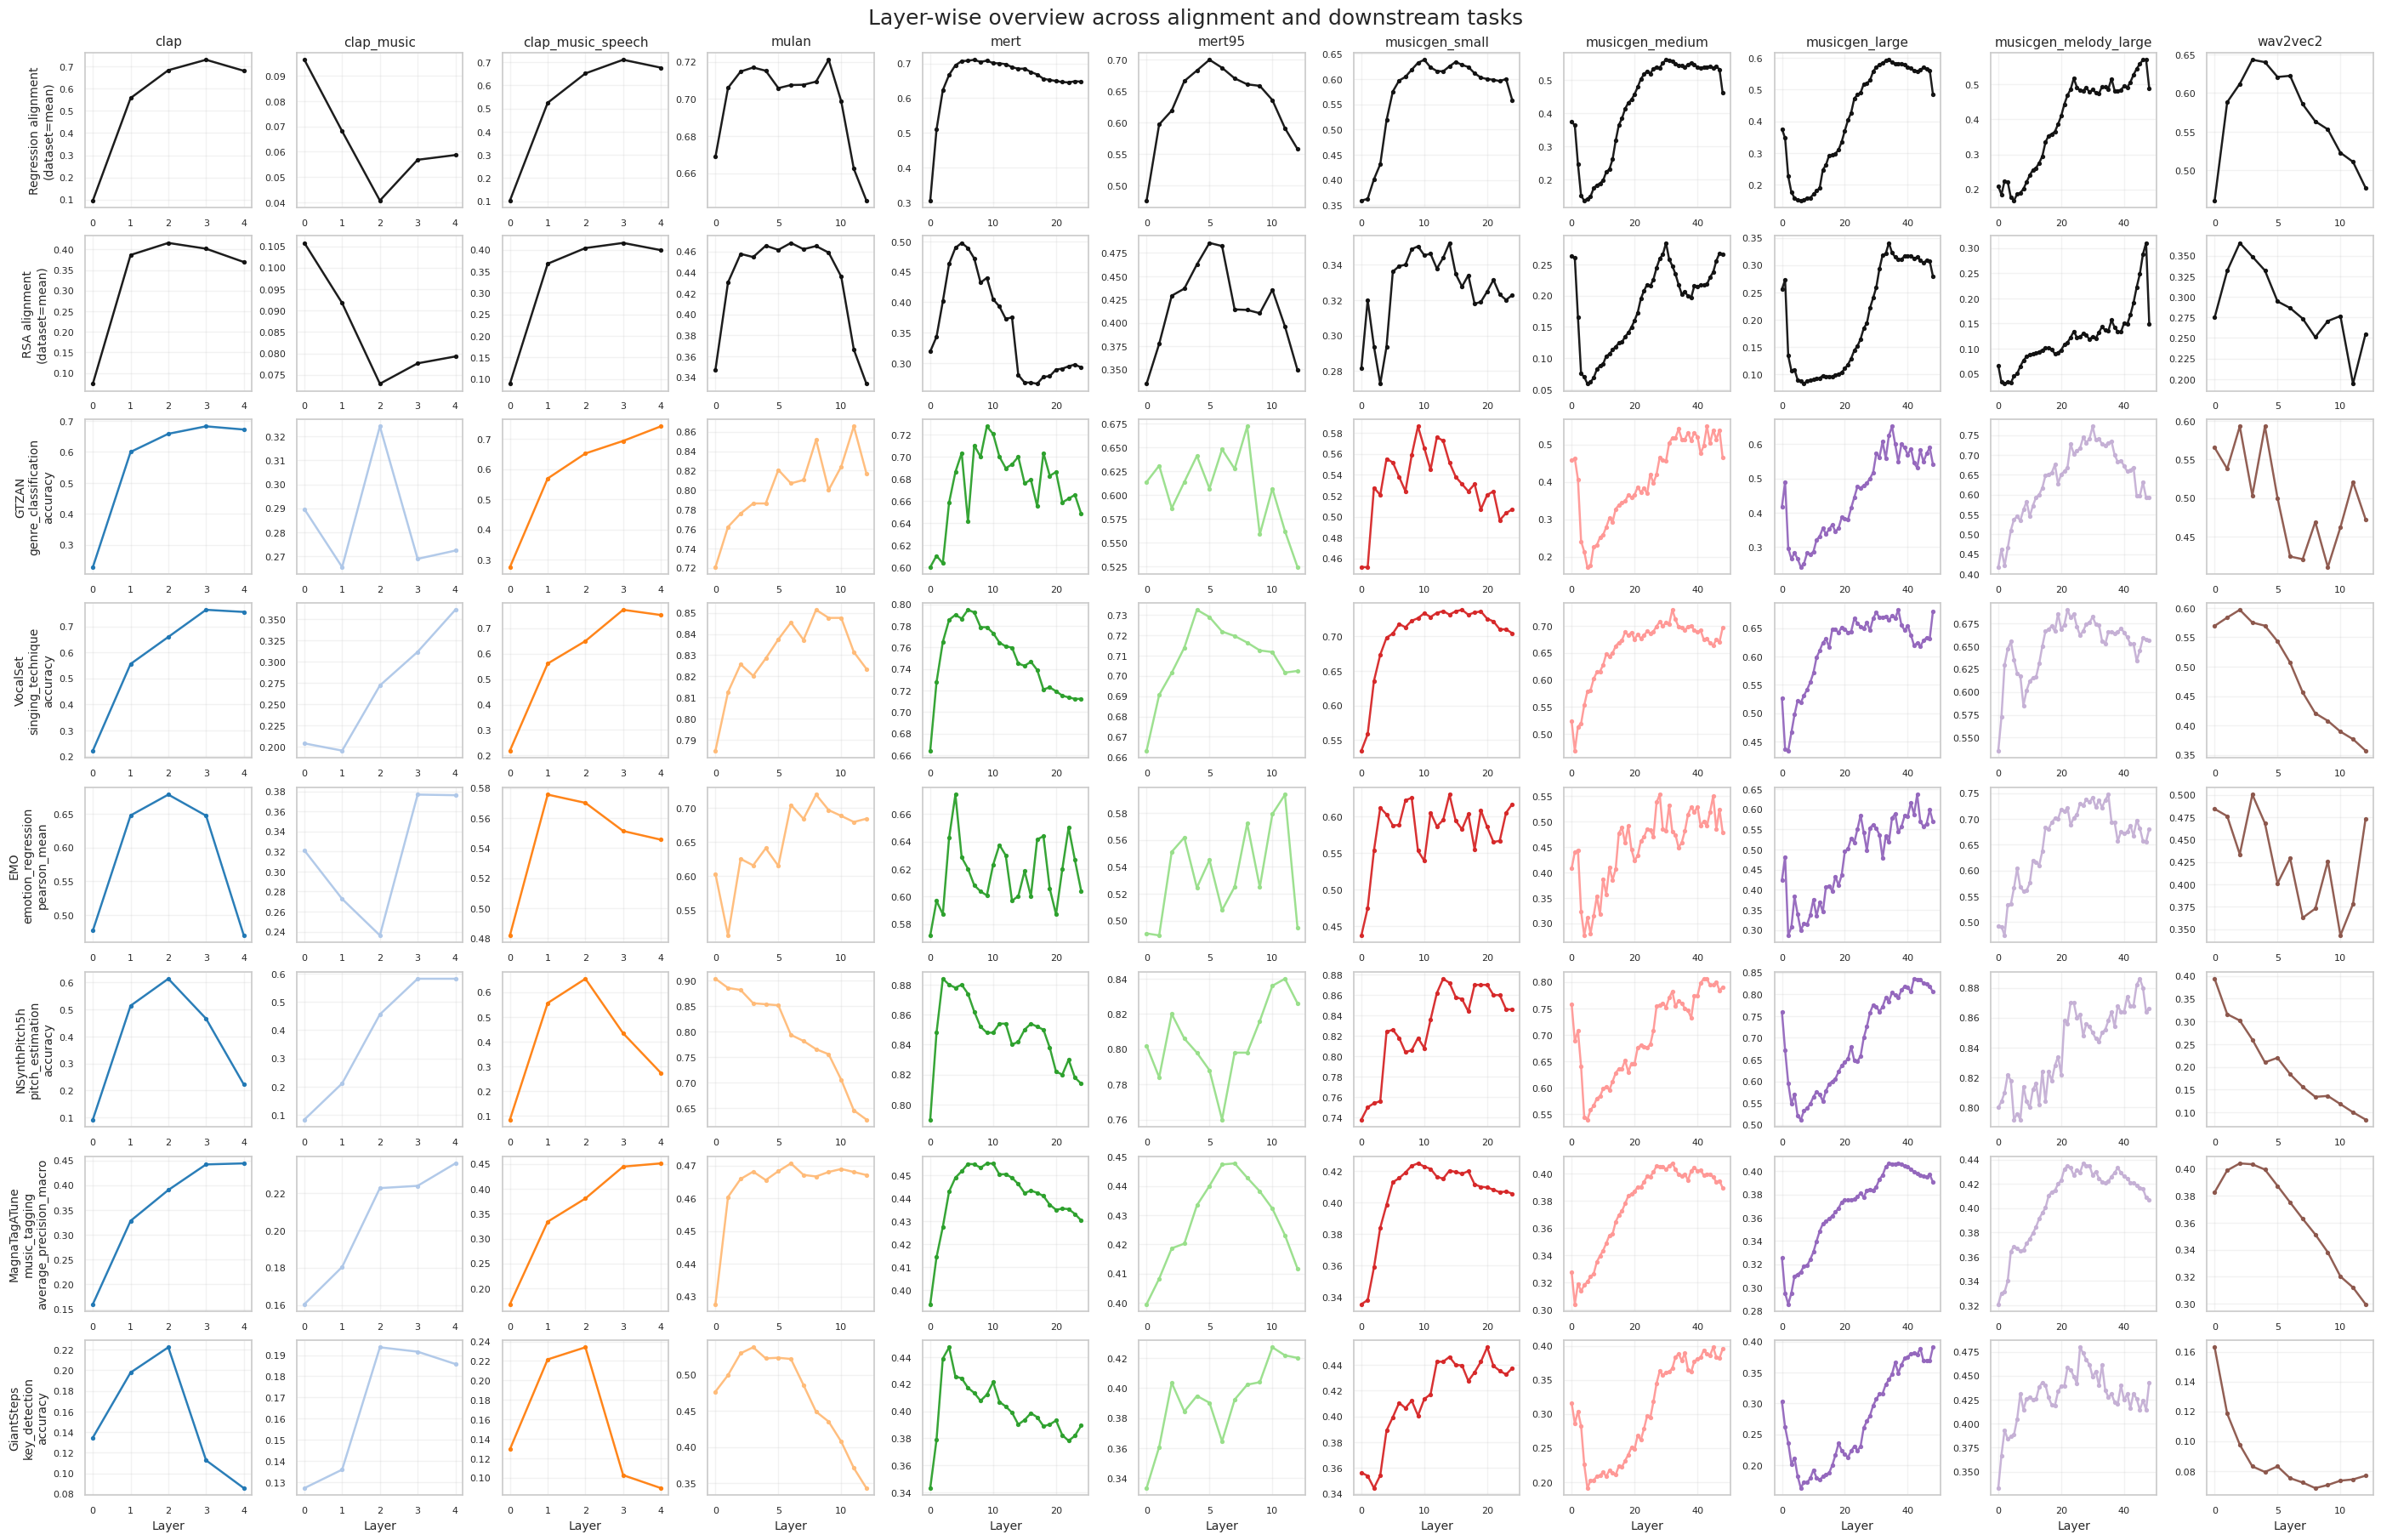

In [4]:
alignment_mean = (
    merged_layerwise[
        (merged_layerwise['alignment_dataset'] == ALIGNMENT_DATASET)
        & (merged_layerwise['layer_index'].notna())
    ]
    .sort_values(['alignment_kind', 'model_name', 'layer_index'])
    .drop_duplicates(['alignment_kind', 'model_name', 'alignment_representation_name'])
    .copy()
)
layer_only = summary[summary['layer_index'].notna()].copy()

overview_rows = [
    ('alignment', 'regression'),
    ('alignment', 'rsa'),
] + [('task', dataset_task) for dataset_task in task_order]

row_labels = {
    ('alignment', 'regression'): f"Regression alignment\n(dataset={ALIGNMENT_DATASET})",
    ('alignment', 'rsa'): f"RSA alignment\n(dataset={ALIGNMENT_DATASET})",
}
for dataset_task in task_order:
    subset = layer_only[layer_only['dataset_task'] == dataset_task]
    metric_name = subset['primary_metric_name'].iloc[0] if len(subset) else 'metric'
    title_dataset, title_task = str(dataset_task).split(' / ', 1)
    row_labels[('task', dataset_task)] = f"{title_dataset}\n{title_task}\n{metric_name}"

display(Markdown('## Model-by-Model Layer Overview'))
fig, axes = plt.subplots(len(overview_rows), len(model_order), figsize=(28, 18), constrained_layout=True)

for row_index, row_key in enumerate(overview_rows):
    row_type, row_name = row_key
    for col_index, model_name in enumerate(model_order):
        ax = axes[row_index, col_index]
        if row_type == 'alignment':
            subset = alignment_mean[
                (alignment_mean['alignment_kind'] == row_name)
                & (alignment_mean['model_name'] == model_name)
            ].copy().sort_values('layer_index')
            x_values = subset['layer_index']
            y_values = subset['alignment_score']
            line_color = '#111111'
        else:
            subset = layer_only[
                (layer_only['dataset_task'] == row_name)
                & (layer_only['model_name'] == model_name)
            ].copy().sort_values('layer_index')
            x_values = subset['layer_index']
            y_values = subset['primary_metric_value']
            line_color = palette[str(model_name)]

        if len(subset) > 0:
            ax.plot(x_values, y_values, color=line_color, linewidth=1.8, marker='o', markersize=2.8, alpha=0.95)

        if row_index == 0:
            ax.set_title(str(model_name), fontsize=11)
        if col_index == 0:
            ax.set_ylabel(row_labels[row_key], fontsize=10)
        if row_index == len(overview_rows) - 1:
            ax.set_xlabel('Layer', fontsize=10)

        ax.grid(alpha=0.25)
        ax.tick_params(labelsize=8)

fig.suptitle('Layer-wise overview across alignment and downstream tasks', fontsize=18)
plt.show()

## All Models: Alignment by Relative Layer Depth

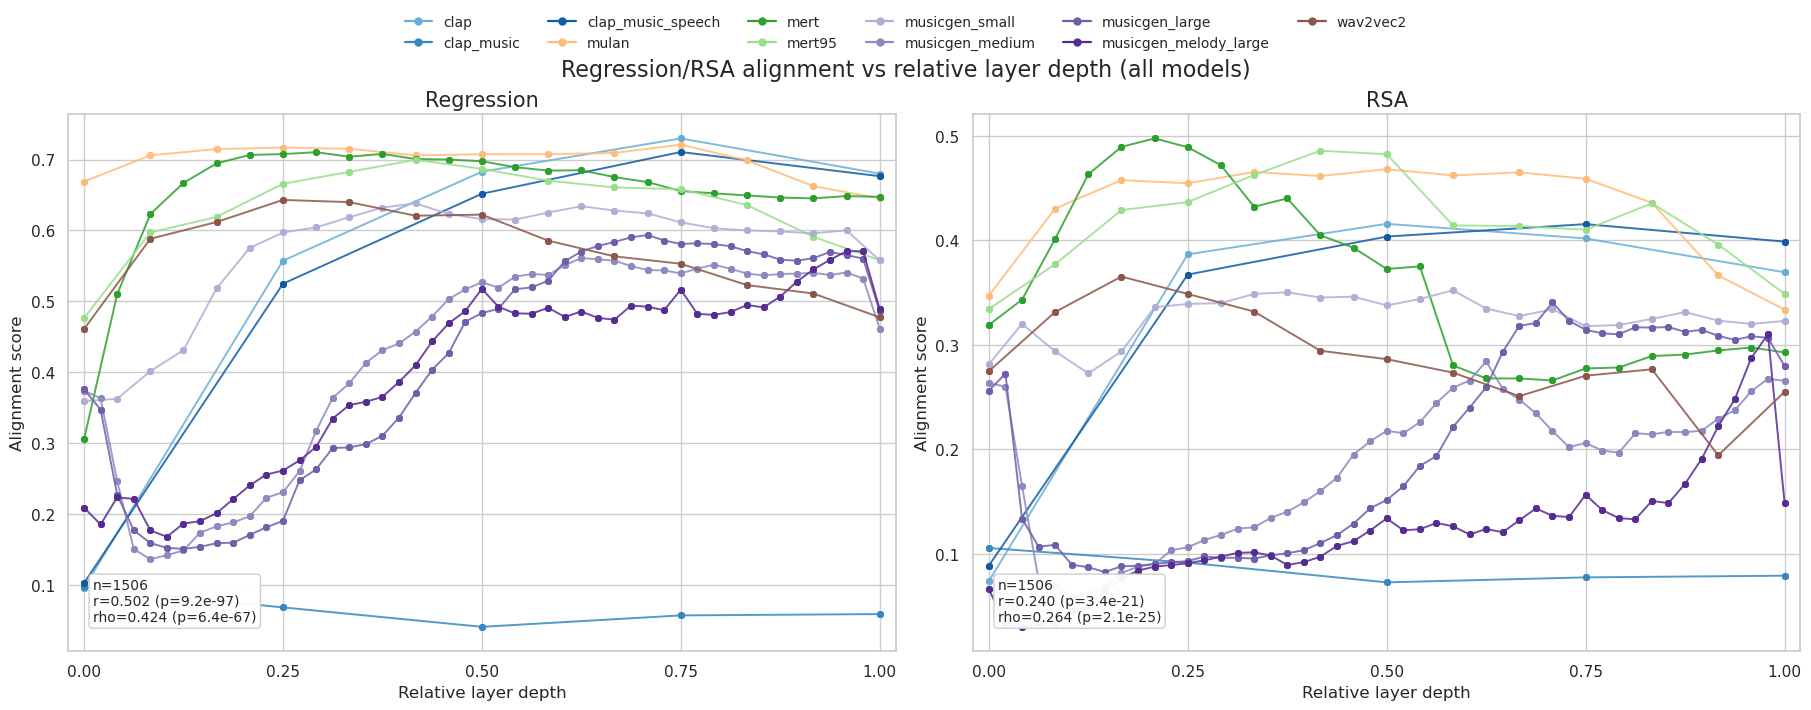

### Correlation Summary (Relative depth vs Alignment score)

,alignment_kind,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,Regression,1506,0.501593,9.173521e-97,0.424451,6.439136e-67
1,RSA,1506,0.240115,3.419371e-21,0.263903,2.051174e-25


In [14]:
from matplotlib.lines import Line2D

layer_alignment = merged_layerwise[
    (merged_layerwise['alignment_dataset'] == ALIGNMENT_DATASET)
    & (merged_layerwise['alignment_kind'].isin(['regression', 'rsa']))
    & (merged_layerwise['layer_index'].notna())
].copy()

max_layer_lookup = (
    layer_alignment.groupby('model_name', observed=True)['layer_index']
    .max()
    .rename('max_layer_index')
    .reset_index()
)
layer_alignment = layer_alignment.merge(max_layer_lookup, on='model_name', how='left')
layer_alignment['layer_ratio'] = np.where(
    layer_alignment['max_layer_index'] > 0,
    layer_alignment['layer_index'] / layer_alignment['max_layer_index'],
    0.0,
)

# Family-aware palette: CLAP=blue gradient, MusicGen=purple gradient, others keep existing colors.
plot_palette = {m: palette[m] for m in model_order}
clap_family = [m for m in model_order if str(m).startswith('clap')]
musicgen_family = [m for m in model_order if str(m).startswith('musicgen')]
if len(clap_family):
    clap_colors = sns.color_palette('Blues', n_colors=len(clap_family) + 2)[2:]
    for model_name, color in zip(clap_family, clap_colors):
        plot_palette[model_name] = color
if len(musicgen_family):
    musicgen_colors = sns.color_palette('Purples', n_colors=len(musicgen_family) + 2)[2:]
    for model_name, color in zip(musicgen_family, musicgen_colors):
        plot_palette[model_name] = color

display(Markdown('## All Models: Alignment by Relative Layer Depth'))
fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 6.5),
    sharex=True,
    constrained_layout=True,
)
kind_specs = [('regression', 'Regression'), ('rsa', 'RSA')]

for ax, (kind_name, panel_title) in zip(axes, kind_specs):
    subset_kind = layer_alignment[layer_alignment['alignment_kind'] == kind_name].copy()
    subset_kind = subset_kind.sort_values(['model_name', 'layer_index'])

    for model_name in model_order:
        model_subset = subset_kind[subset_kind['model_name'] == model_name]
        if len(model_subset) == 0:
            continue
        ax.plot(
            model_subset['layer_ratio'],
            model_subset['alignment_score'],
            color=plot_palette[model_name],
            linewidth=1.4,
            marker='o',
            markersize=3.8,
            alpha=0.85,
        )

    x = subset_kind['layer_ratio'].to_numpy(dtype=float)
    y = subset_kind['alignment_score'].to_numpy(dtype=float)
    if len(subset_kind) >= 3 and np.unique(x).size >= 2:
        pearson_val = pearsonr(x, y)
        spearman_val = spearmanr(x, y)
        ax.text(
            0.03,
            0.05,
            (
                f'n={len(subset_kind)}\n'
                f'r={pearson_val.statistic:.3f} (p={pearson_val.pvalue:.2g})\n'
                f'rho={spearman_val.statistic:.3f} (p={spearman_val.pvalue:.2g})'
            ),
            transform=ax.transAxes,
            ha='left',
            va='bottom',
            fontsize=10,
            bbox=dict(boxstyle='round,pad=0.28', facecolor='white', edgecolor='0.8', alpha=0.95),
        )

    ax.set_title(panel_title, fontsize=15)
    ax.set_xlabel('Relative layer depth', fontsize=12)
    ax.set_ylabel('Alignment score', fontsize=12)
    ax.set_xlim(-0.02, 1.02)
    ax.set_xticks(np.linspace(0.0, 1.0, 5))

legend_handles = [
    Line2D([0], [0], marker='o', linestyle='-', color=plot_palette[m], label=m, markersize=5, linewidth=1.6)
    for m in model_order
]
fig.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.08),
    ncol=min(6, len(legend_handles)),
    frameon=False,
    fontsize=10,
)
fig.suptitle('Regression/RSA alignment vs relative layer depth (all models)', fontsize=16)
plt.show()

corr_rows = []
for kind_name, panel_title in kind_specs:
    subset_kind = layer_alignment[layer_alignment['alignment_kind'] == kind_name].copy()
    if len(subset_kind) < 3:
        continue
    pearson_val = pearsonr(subset_kind['layer_ratio'], subset_kind['alignment_score'])
    spearman_val = spearmanr(subset_kind['layer_ratio'], subset_kind['alignment_score'])
    corr_rows.append({
        'alignment_kind': panel_title,
        'n_points': int(len(subset_kind)),
        'pearson_r': float(pearson_val.statistic),
        'pearson_p': float(pearson_val.pvalue),
        'spearman_rho': float(spearman_val.statistic),
        'spearman_p': float(spearman_val.pvalue),
    })

display(Markdown('### Correlation Summary (Relative depth vs Alignment score)'))
display(pd.DataFrame(corr_rows))

## All Models: Layer-wise Probe Performance

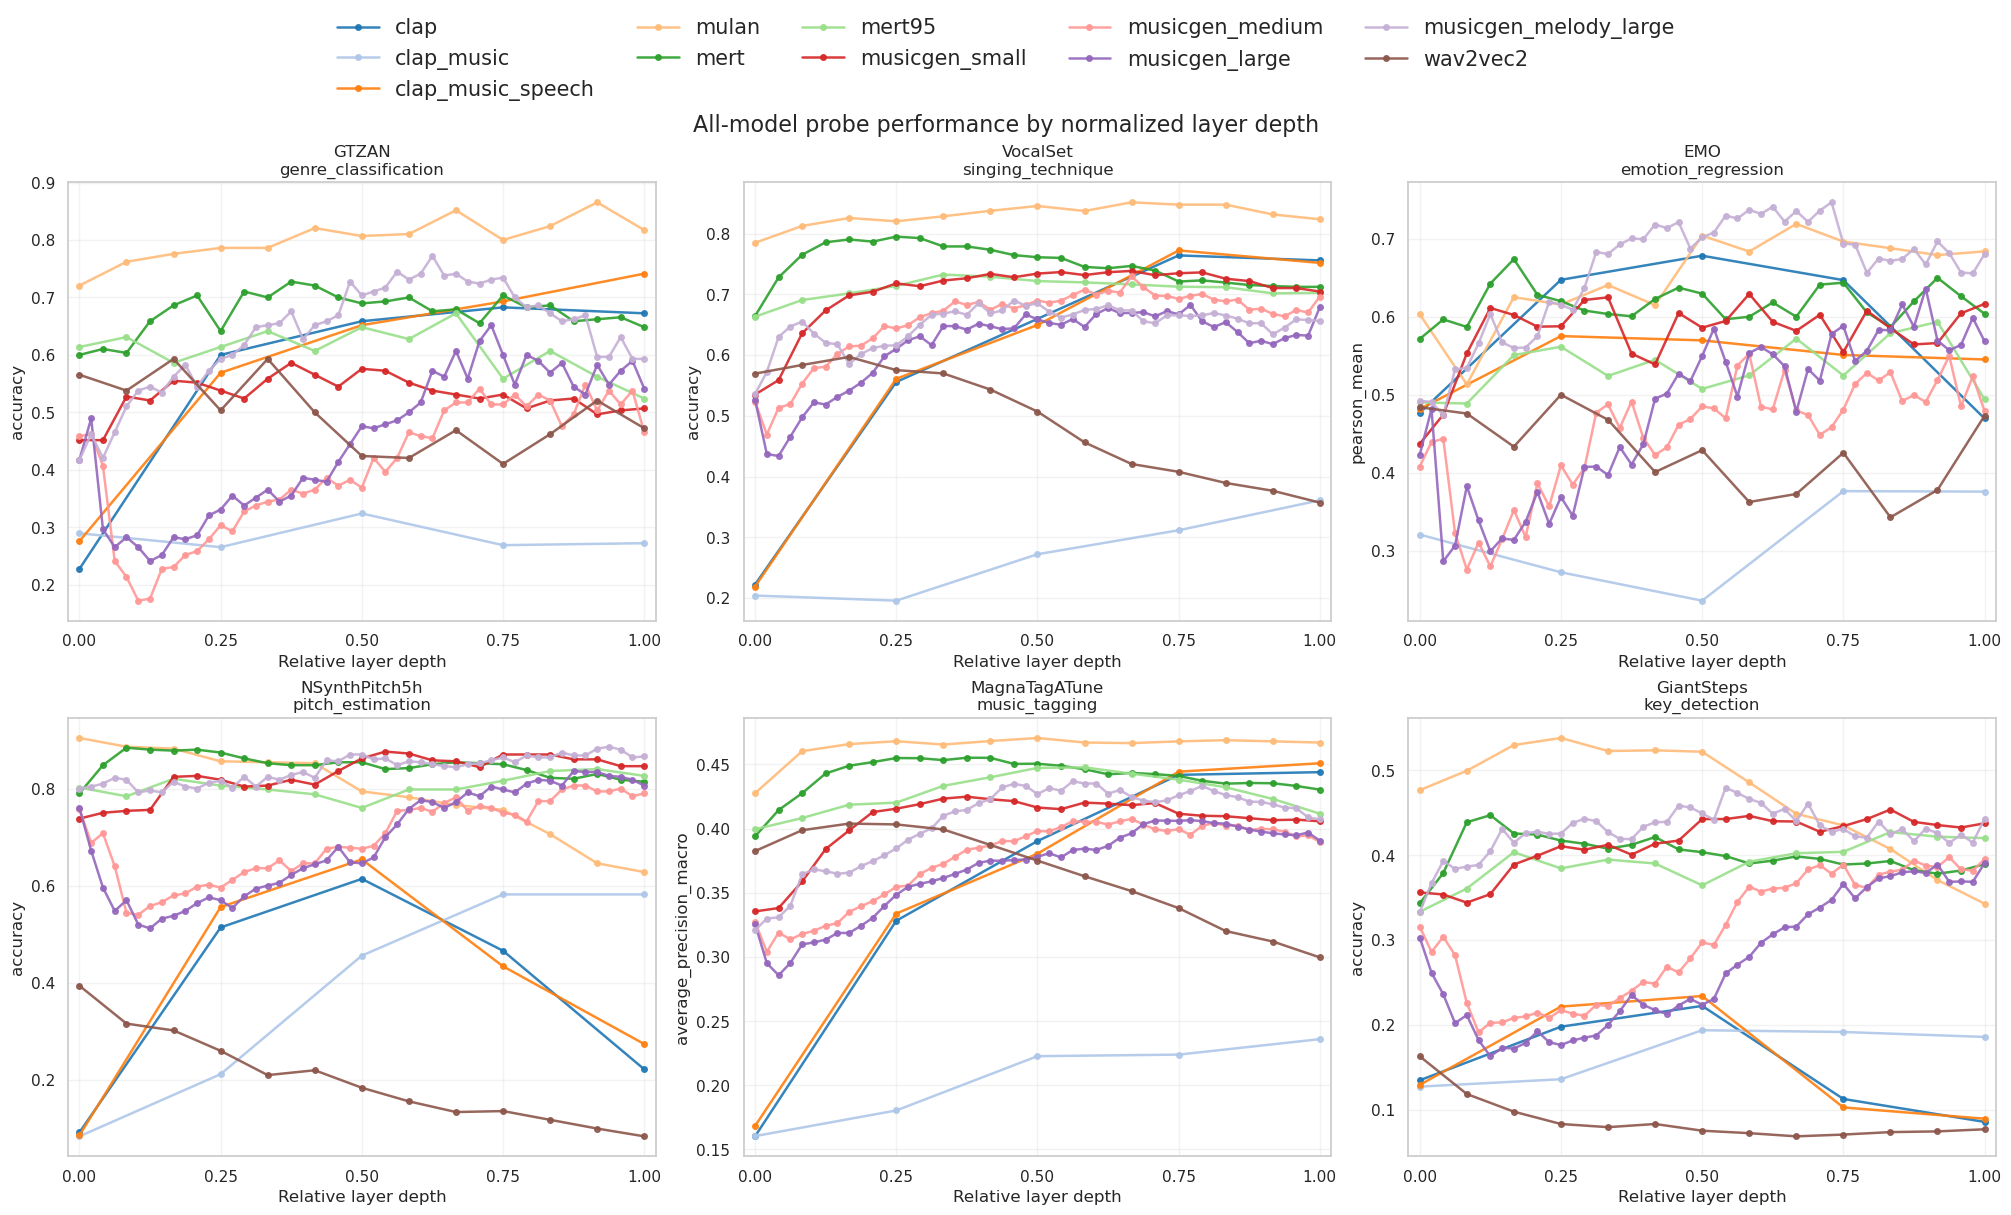

In [6]:
layer_only = summary[summary['layer_index'].notna()].copy()
layer_depth_lookup = layer_only.groupby('model_name', observed=True)['layer_index'].max().rename('max_layer_index').reset_index()
layer_only = layer_only.merge(layer_depth_lookup, on='model_name', how='left')
layer_only['layer_ratio'] = np.where(layer_only['max_layer_index'] > 0, layer_only['layer_index'] / layer_only['max_layer_index'], 0.0)

display(Markdown('## All Models: Layer-wise Probe Performance'))
fig, axes = plt.subplots(2, 3, figsize=(20, 11), constrained_layout=True)
axes = axes.ravel()

for ax, dataset_task in zip(axes, task_order):
    title_dataset, title_task = str(dataset_task).split(' / ', 1)
    task_df = layer_only[layer_only['dataset_task'] == dataset_task].copy().sort_values(['model_name', 'layer_index'])
    if len(task_df) == 0:
        ax.set_title(f'{title_dataset}\n{title_task}')
        ax.set_xlabel('Relative layer depth')
        ax.set_ylabel('Probe performance')
        continue

    metric_name = task_df['primary_metric_name'].iloc[0]
    for model_name in model_order:
        subset = task_df[task_df['model_name'] == model_name].copy()
        if len(subset) == 0:
            continue
        ax.plot(
            subset['layer_ratio'],
            subset['primary_metric_value'],
            color=palette[model_name],
            linewidth=1.8,
            marker='o',
            markersize=4,
            alpha=0.9,
            label=model_name,
        )

    ax.set_title(f'{title_dataset}\n{title_task}')
    ax.set_xlabel('Relative layer depth')
    ax.set_ylabel(metric_name)
    ax.set_xlim(-0.02, 1.02)
    ax.set_xticks(np.linspace(0.0, 1.0, 5))
    ax.grid(alpha=0.25)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.1), ncol=5, frameon=False, fontsize=15)
fig.suptitle('All-model probe performance by normalized layer depth', fontsize=16)
plt.show()


### Verified Numeric Layer Coverage

,dataset_task,model_name,n_layers,first_layer,last_layer,metric
0,GTZAN / genre_classification,clap,5,0,4,accuracy
1,GTZAN / genre_classification,clap_music,5,0,4,accuracy
2,GTZAN / genre_classification,clap_music_speech,5,0,4,accuracy
3,GTZAN / genre_classification,mulan,13,0,12,accuracy
4,GTZAN / genre_classification,mert,25,0,24,accuracy
...,...,...,...,...,...,...
61,GiantSteps / key_detection,musicgen_small,25,0,24,accuracy
62,GiantSteps / key_detection,musicgen_medium,49,0,48,accuracy
63,GiantSteps / key_detection,musicgen_large,49,0,48,accuracy
64,GiantSteps / key_detection,musicgen_melody_large,49,0,48,accuracy


### Last Numeric Layer vs. Final Representation

,dataset_task,model_name,last_layer_representation,last_layer_index,last_layer_score,final_representation,final_score,delta_final_minus_last
0,MagnaTagATune / music_tagging,clap,layer_04,4,0.444029,audio_embedding,0.445823,0.001794
1,VocalSet / singing_technique,clap,layer_04,4,0.755815,audio_embedding,0.708961,-0.046855
2,GiantSteps / key_detection,clap_music_speech,layer_04,4,0.089360,final,0.093516,0.004156
3,NSynthPitch5h / pitch_estimation,clap_music,layer_04,4,0.582000,final,0.580000,-0.002000
4,GiantSteps / key_detection,clap_music,layer_04,4,0.185786,final,0.185786,0.000000
...,...,...,...,...,...,...,...,...
61,EMO / emotion_regression,musicgen_melody_large,layer_48,48,0.680573,final,0.680573,0.000000
62,VocalSet / singing_technique,musicgen_medium,layer_48,48,0.696366,final,0.696366,0.000000
63,VocalSet / singing_technique,musicgen_large,layer_48,48,0.679075,final,0.679075,0.000000
64,NSynthPitch5h / pitch_estimation,musicgen_melody_large,layer_48,48,0.866000,final,0.866000,0.000000


## Layer-wise Probe Performance Overview

### CLAP layer-wise probe performance

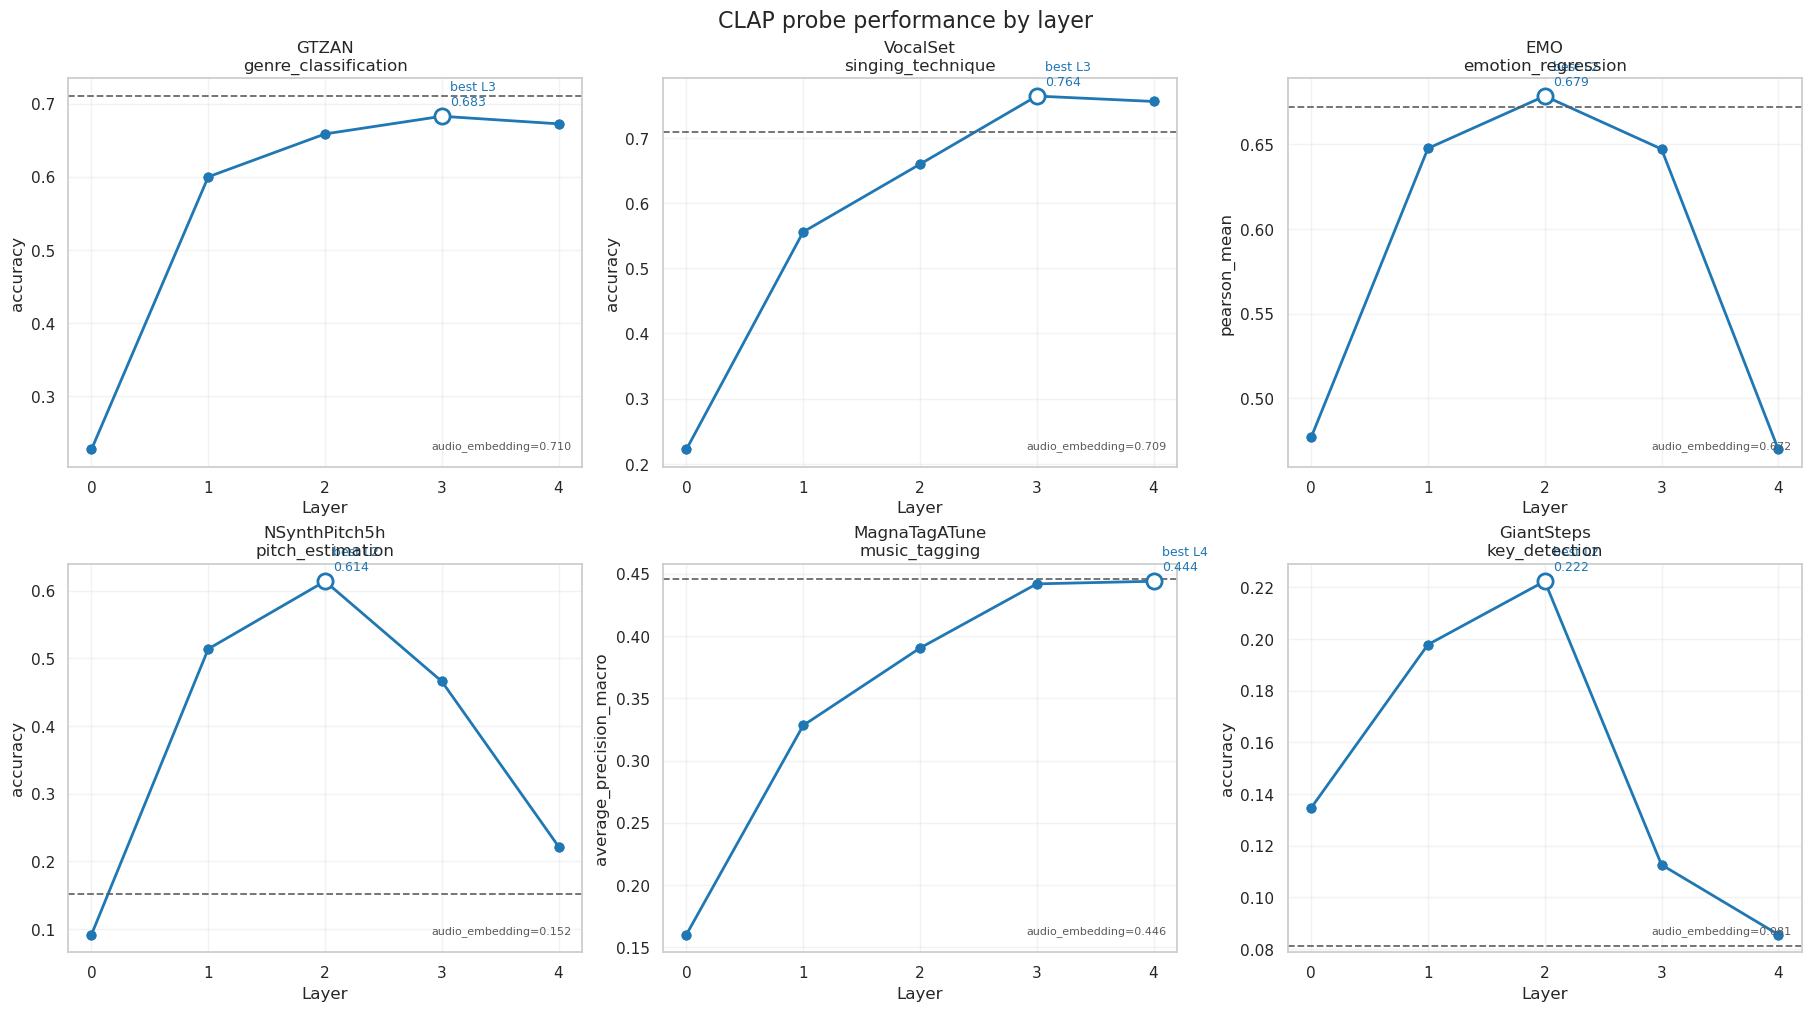

### CLAP_MUSIC layer-wise probe performance

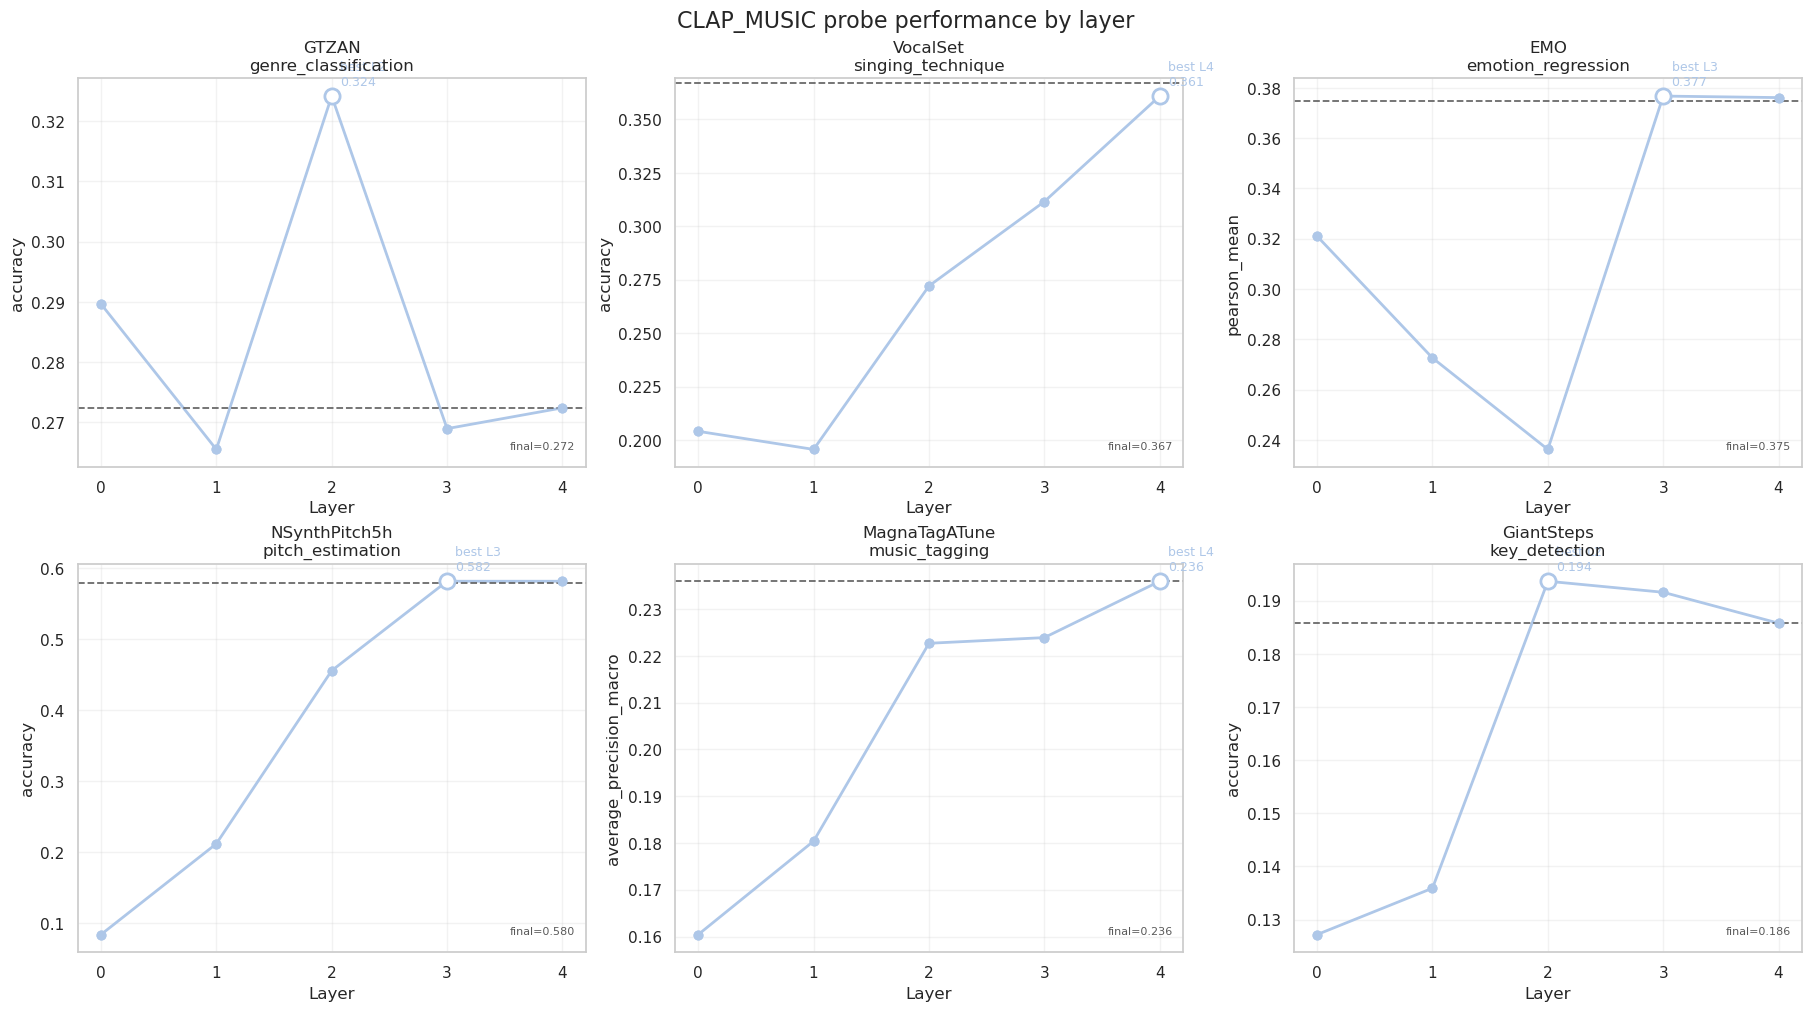

### CLAP_MUSIC_SPEECH layer-wise probe performance

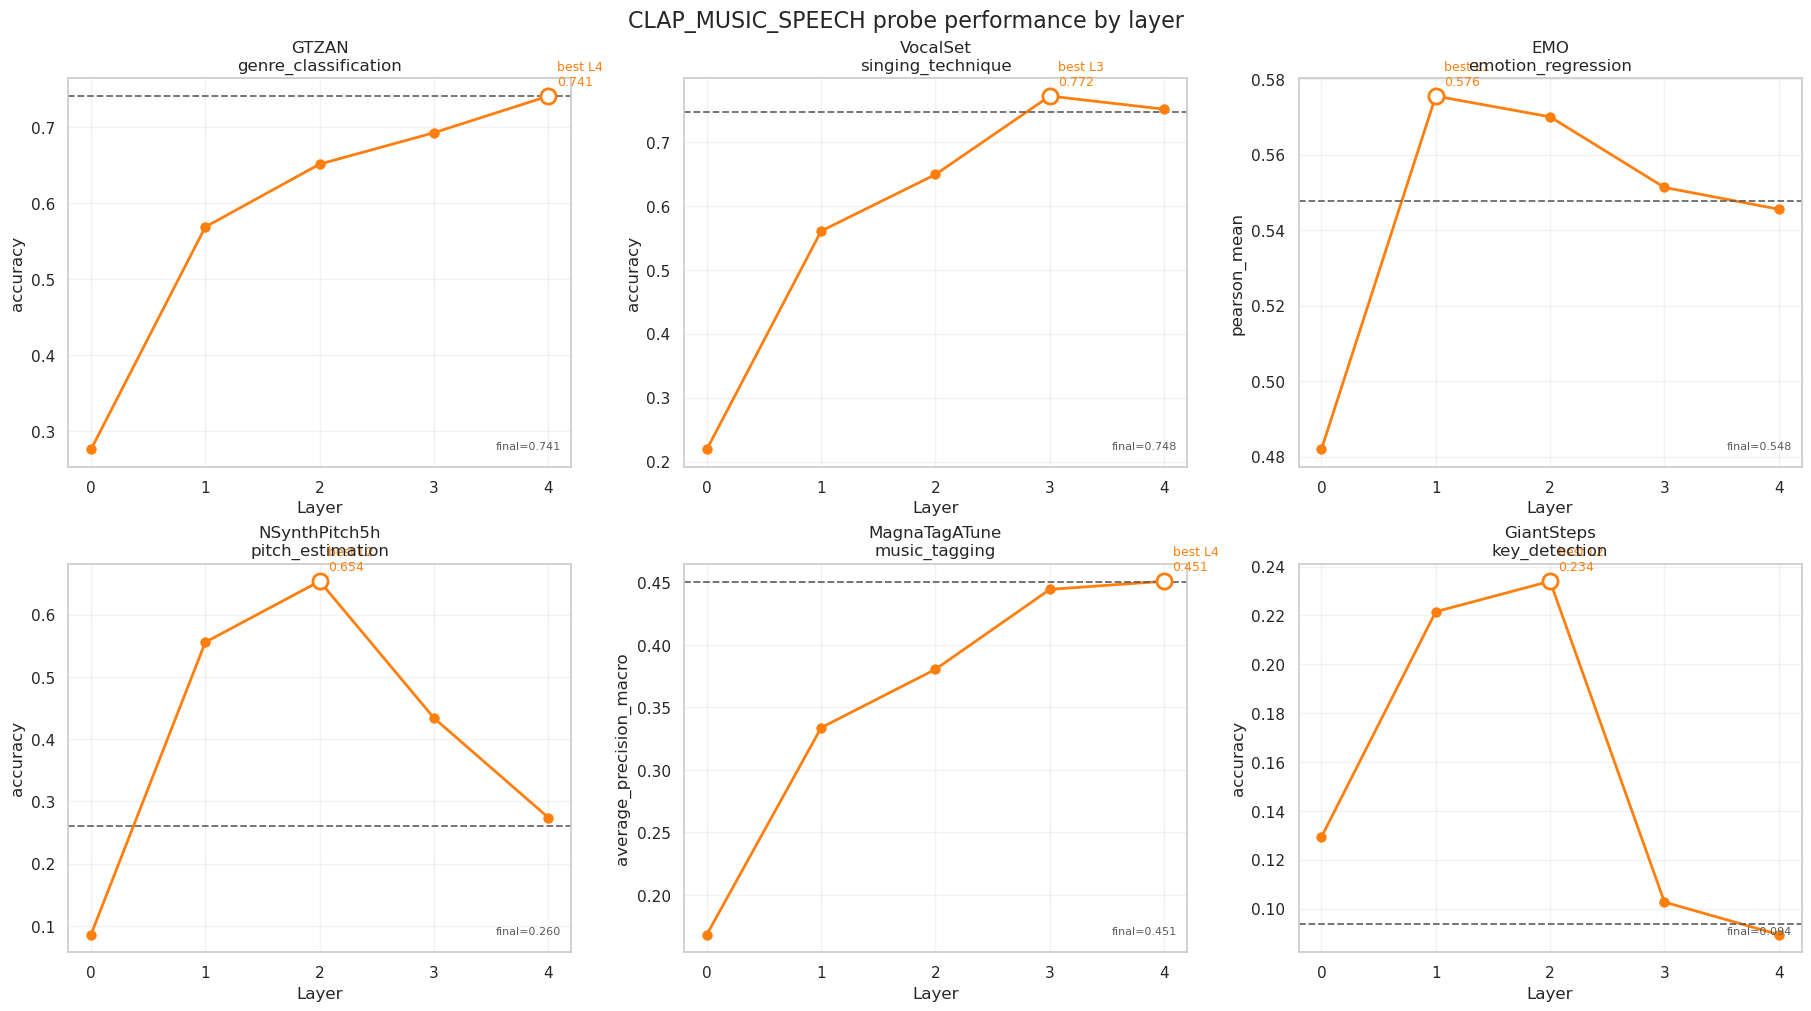

### MULAN layer-wise probe performance

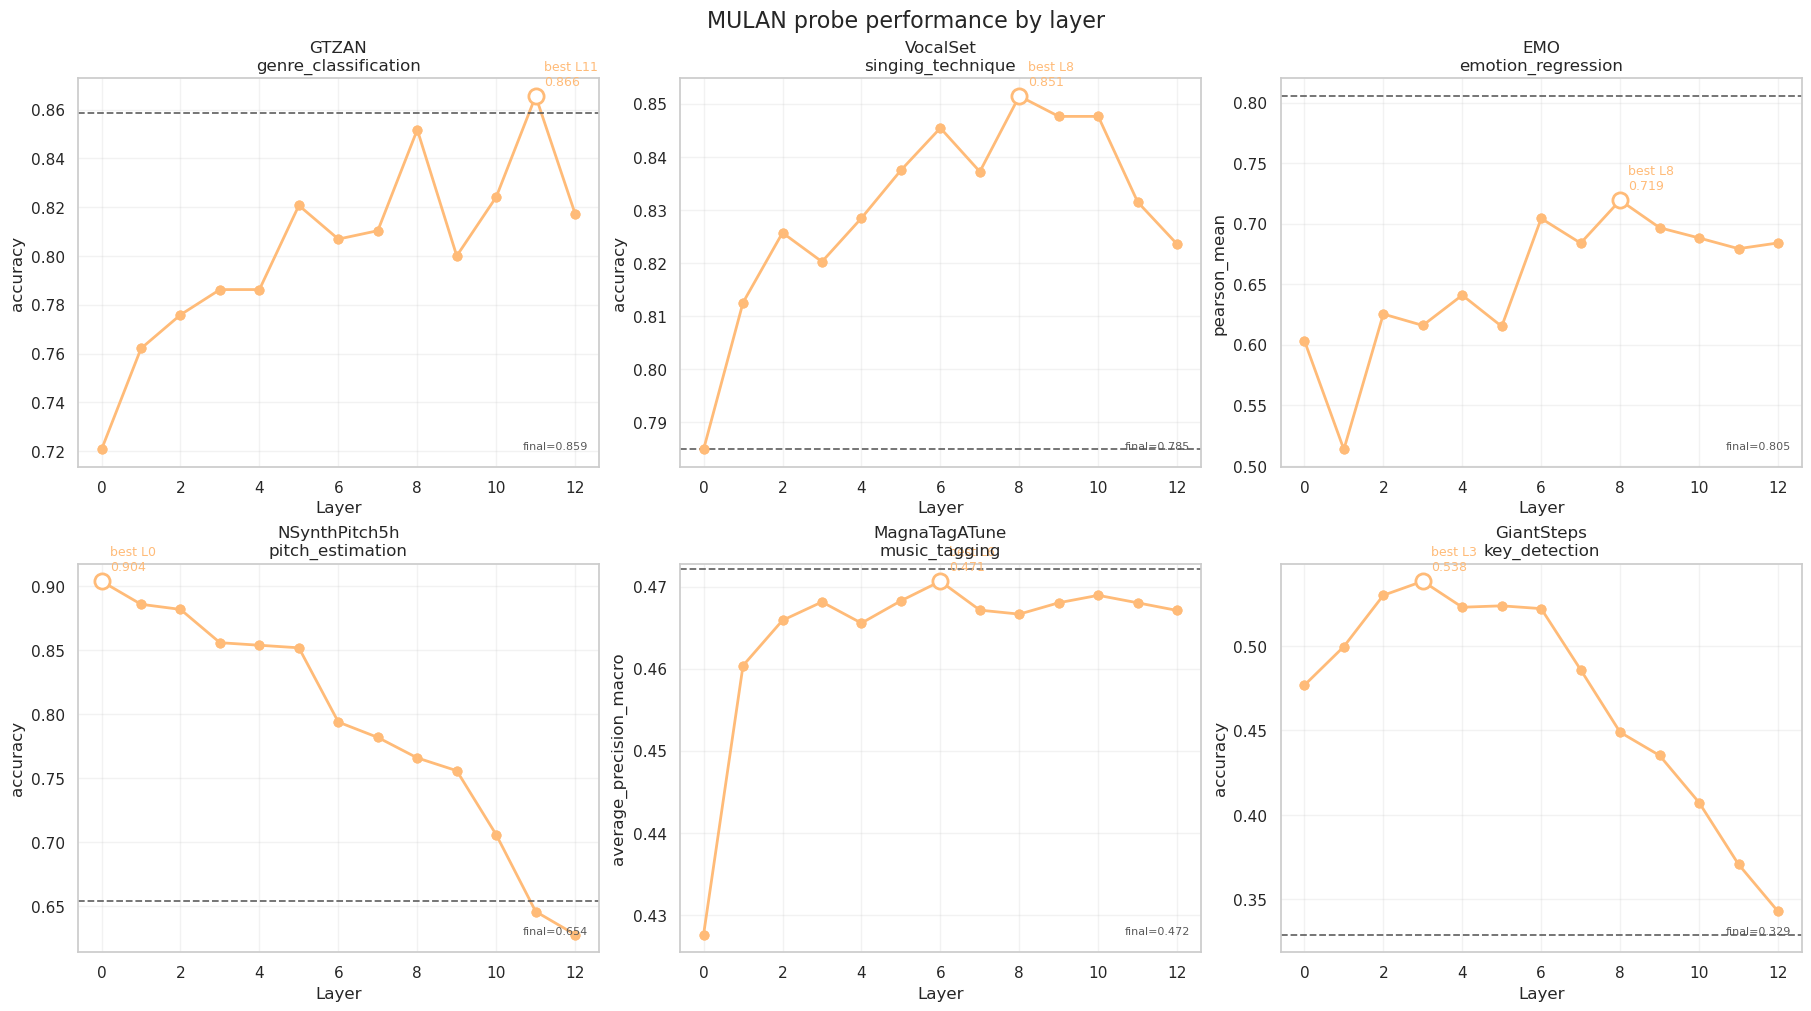

### MERT layer-wise probe performance

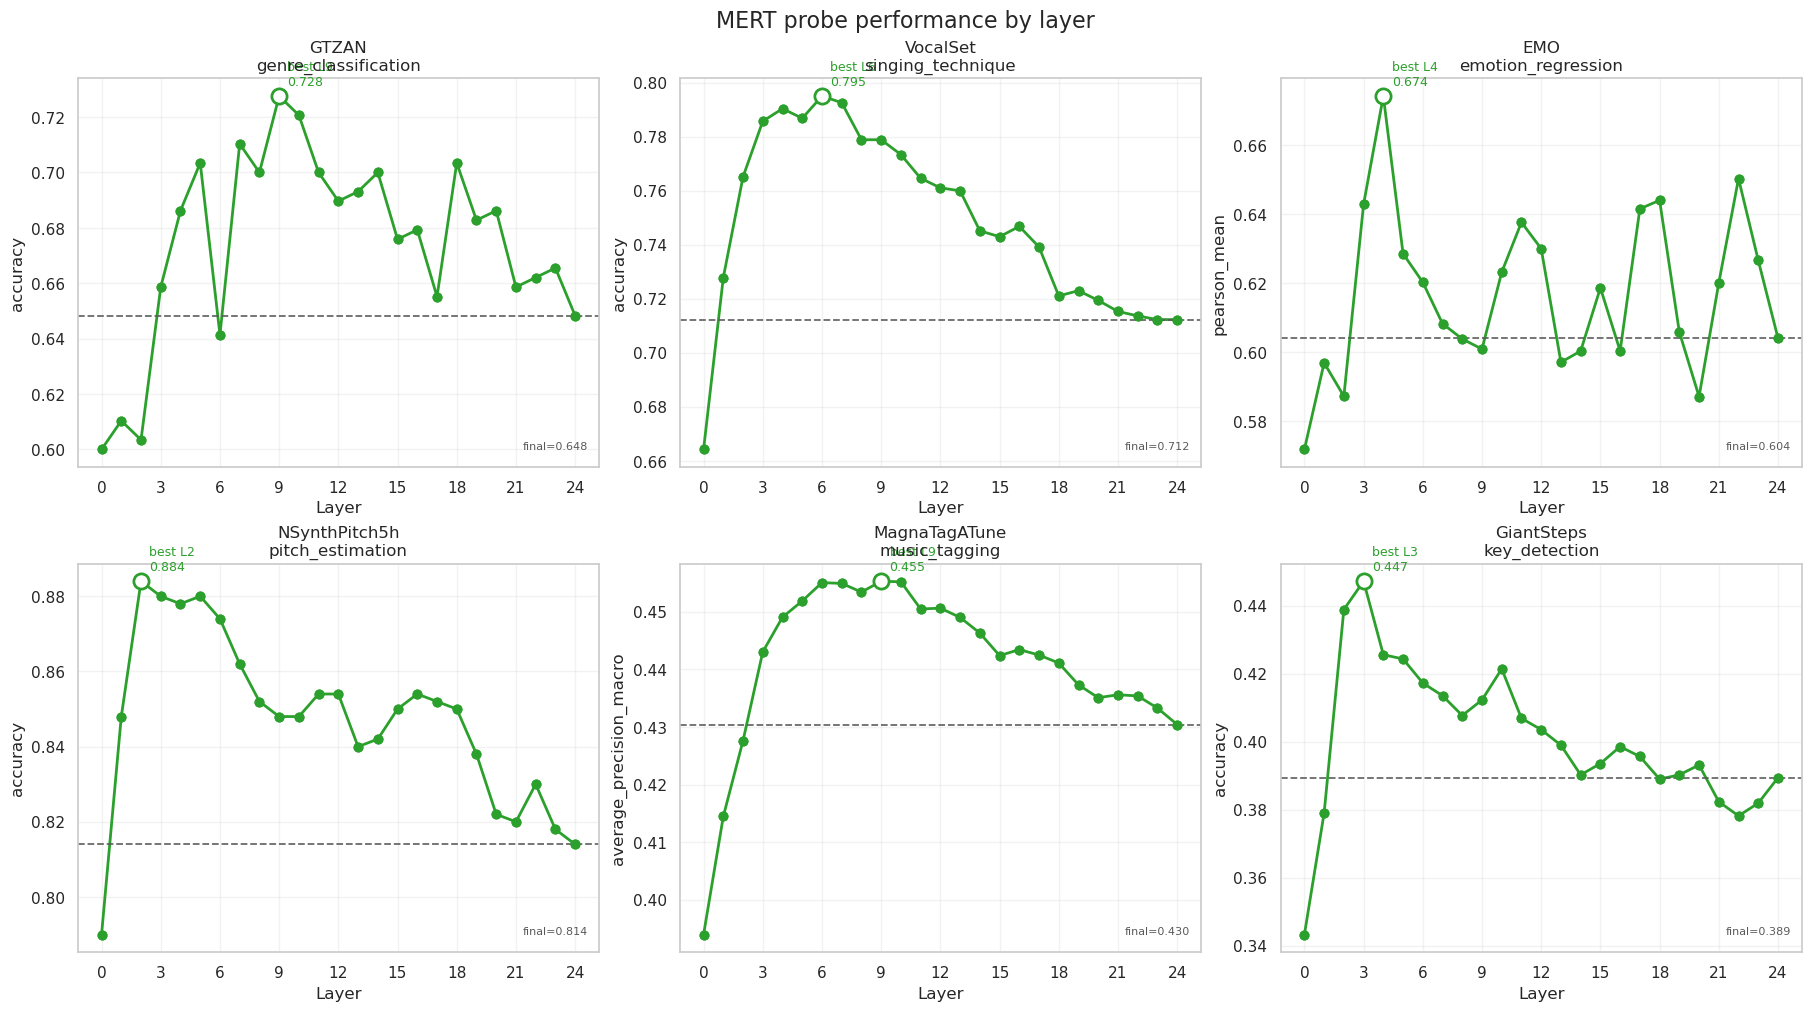

### MERT95 layer-wise probe performance

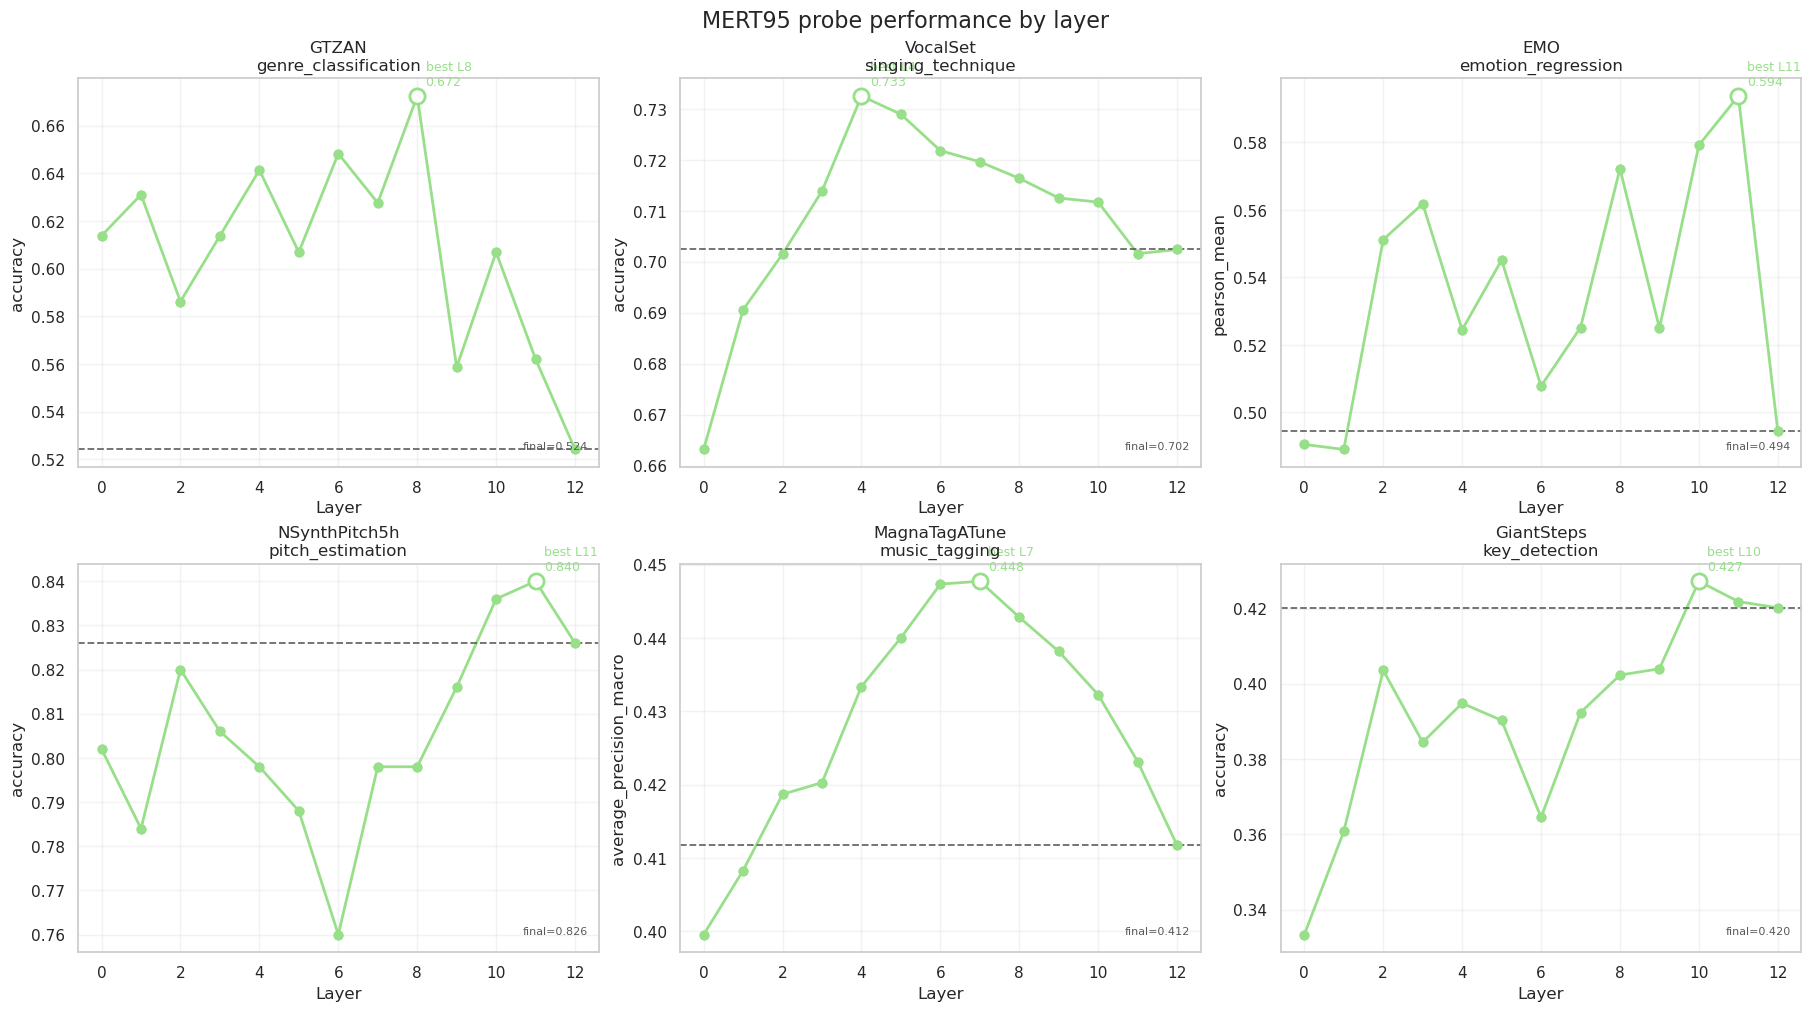

### MUSICGEN_SMALL layer-wise probe performance

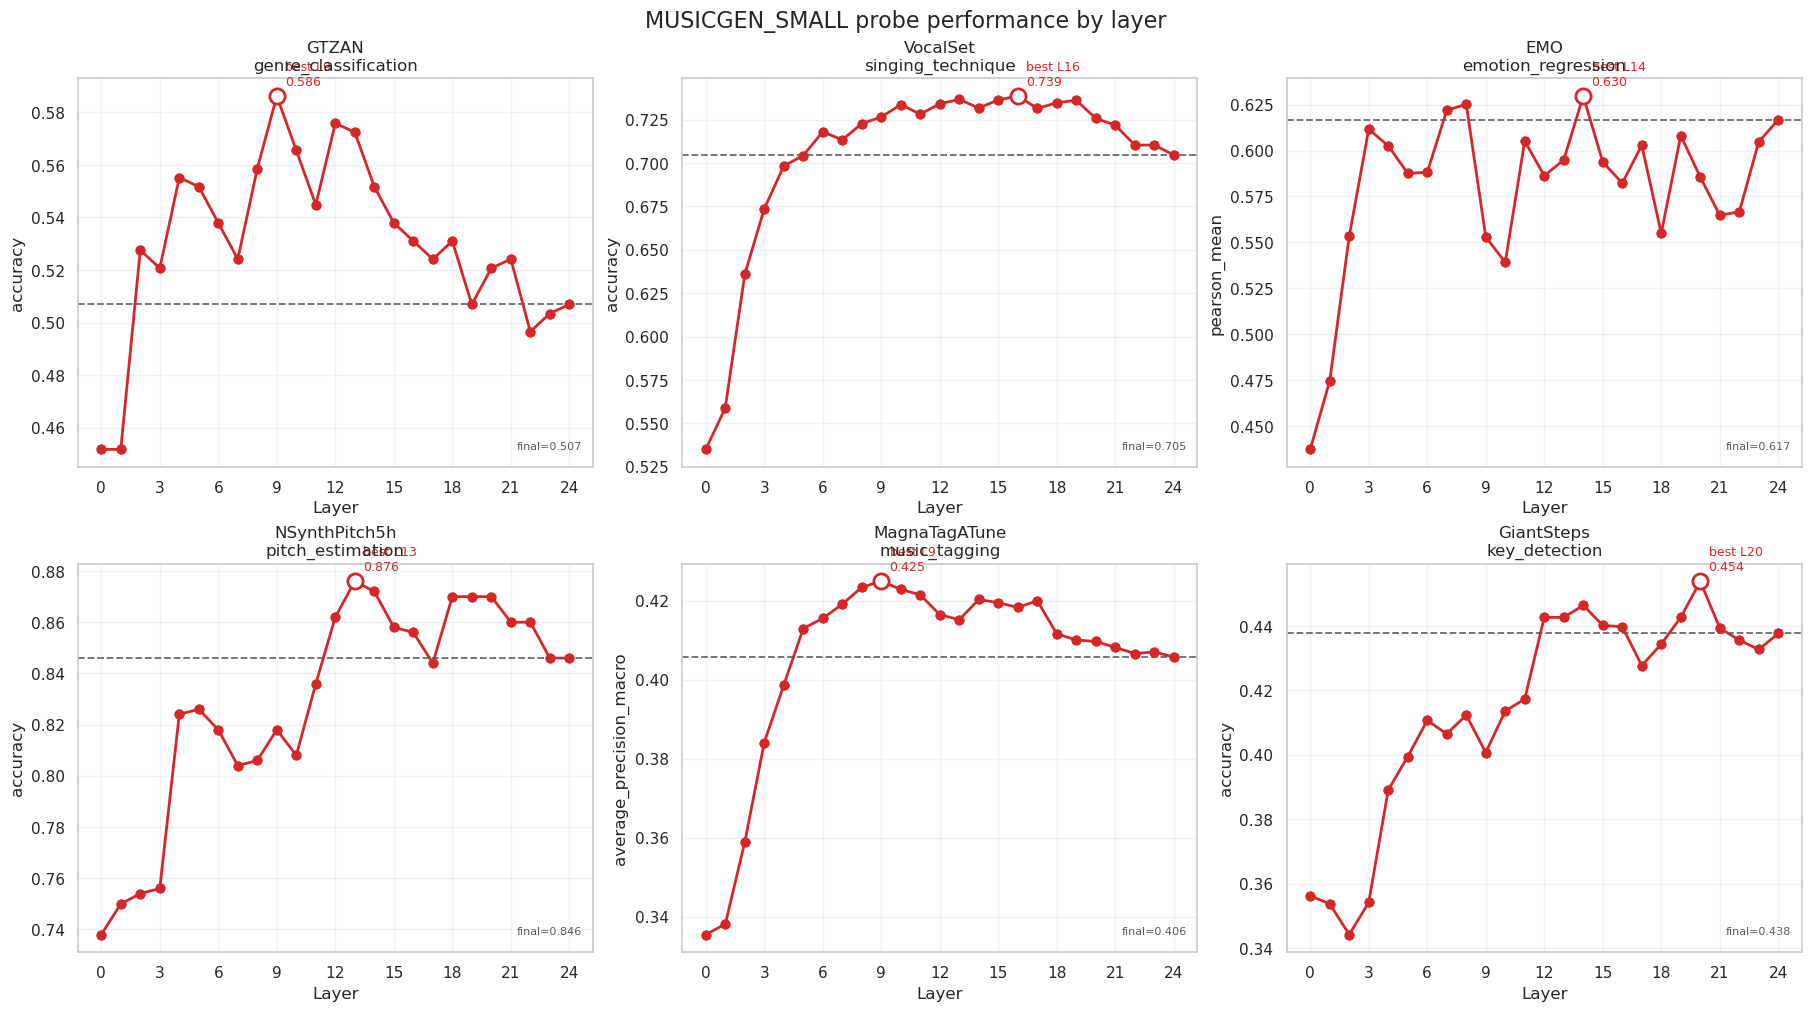

### MUSICGEN_MEDIUM layer-wise probe performance

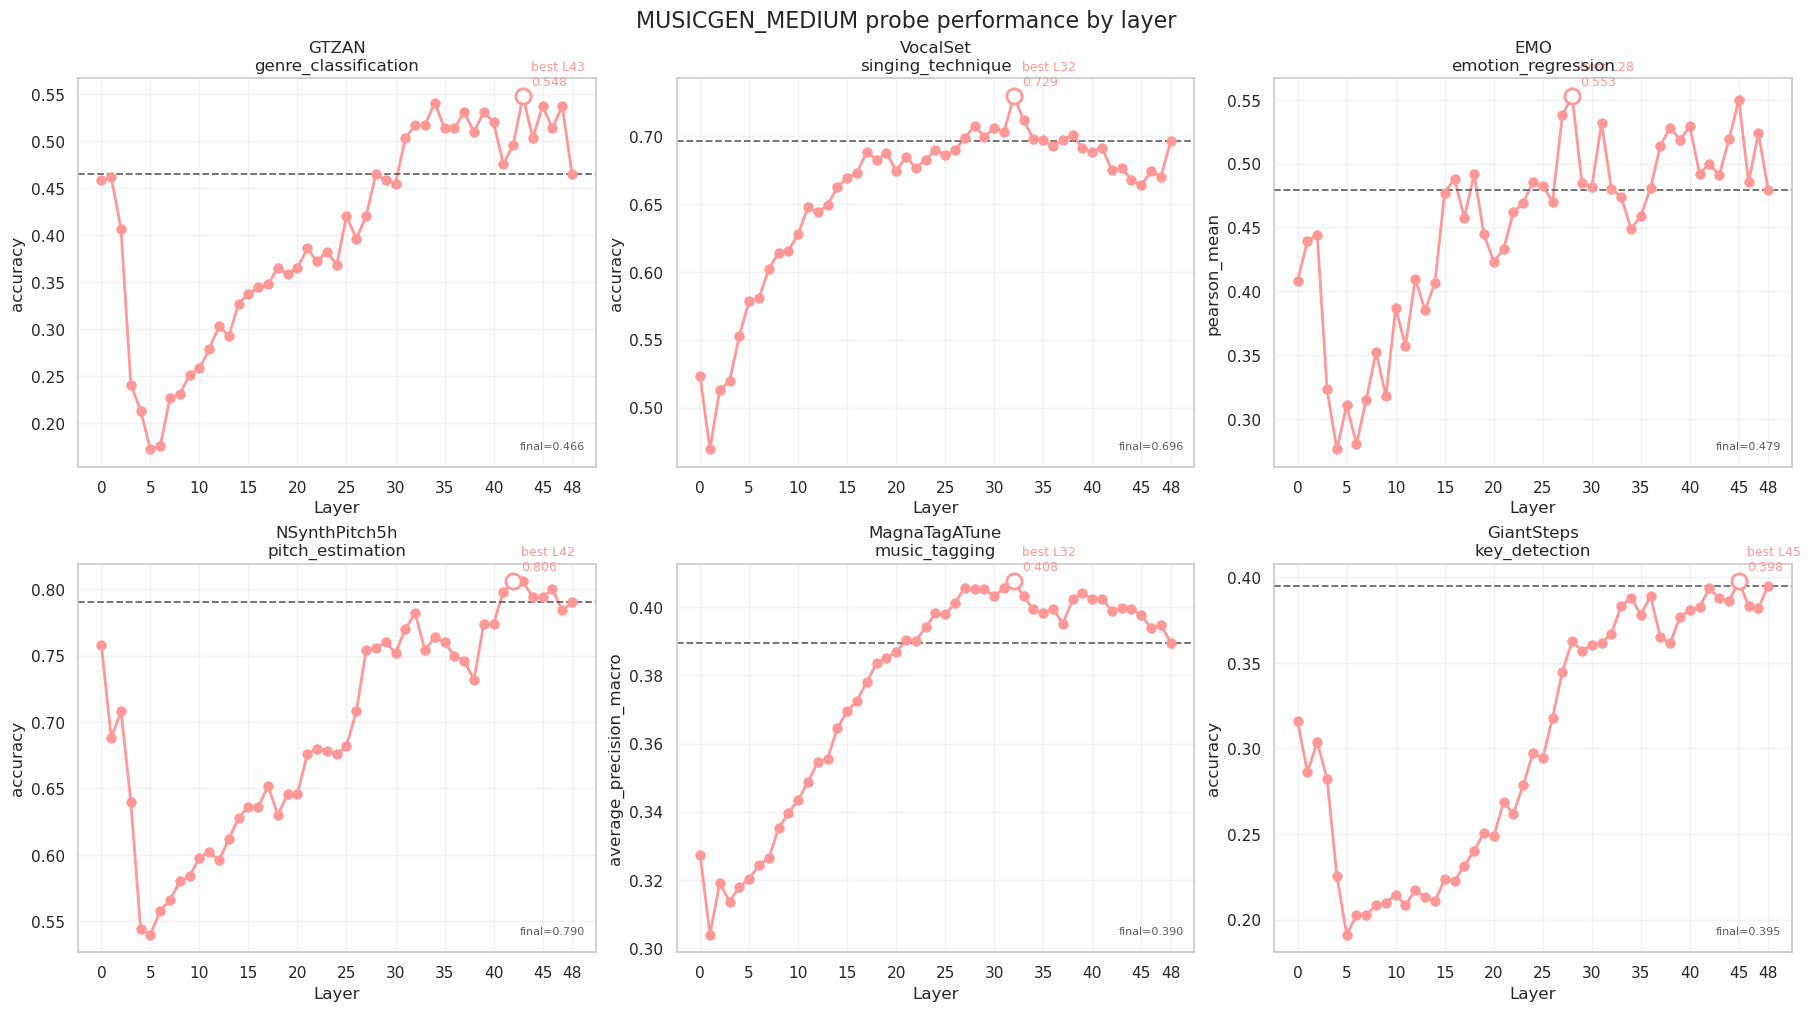

### MUSICGEN_LARGE layer-wise probe performance

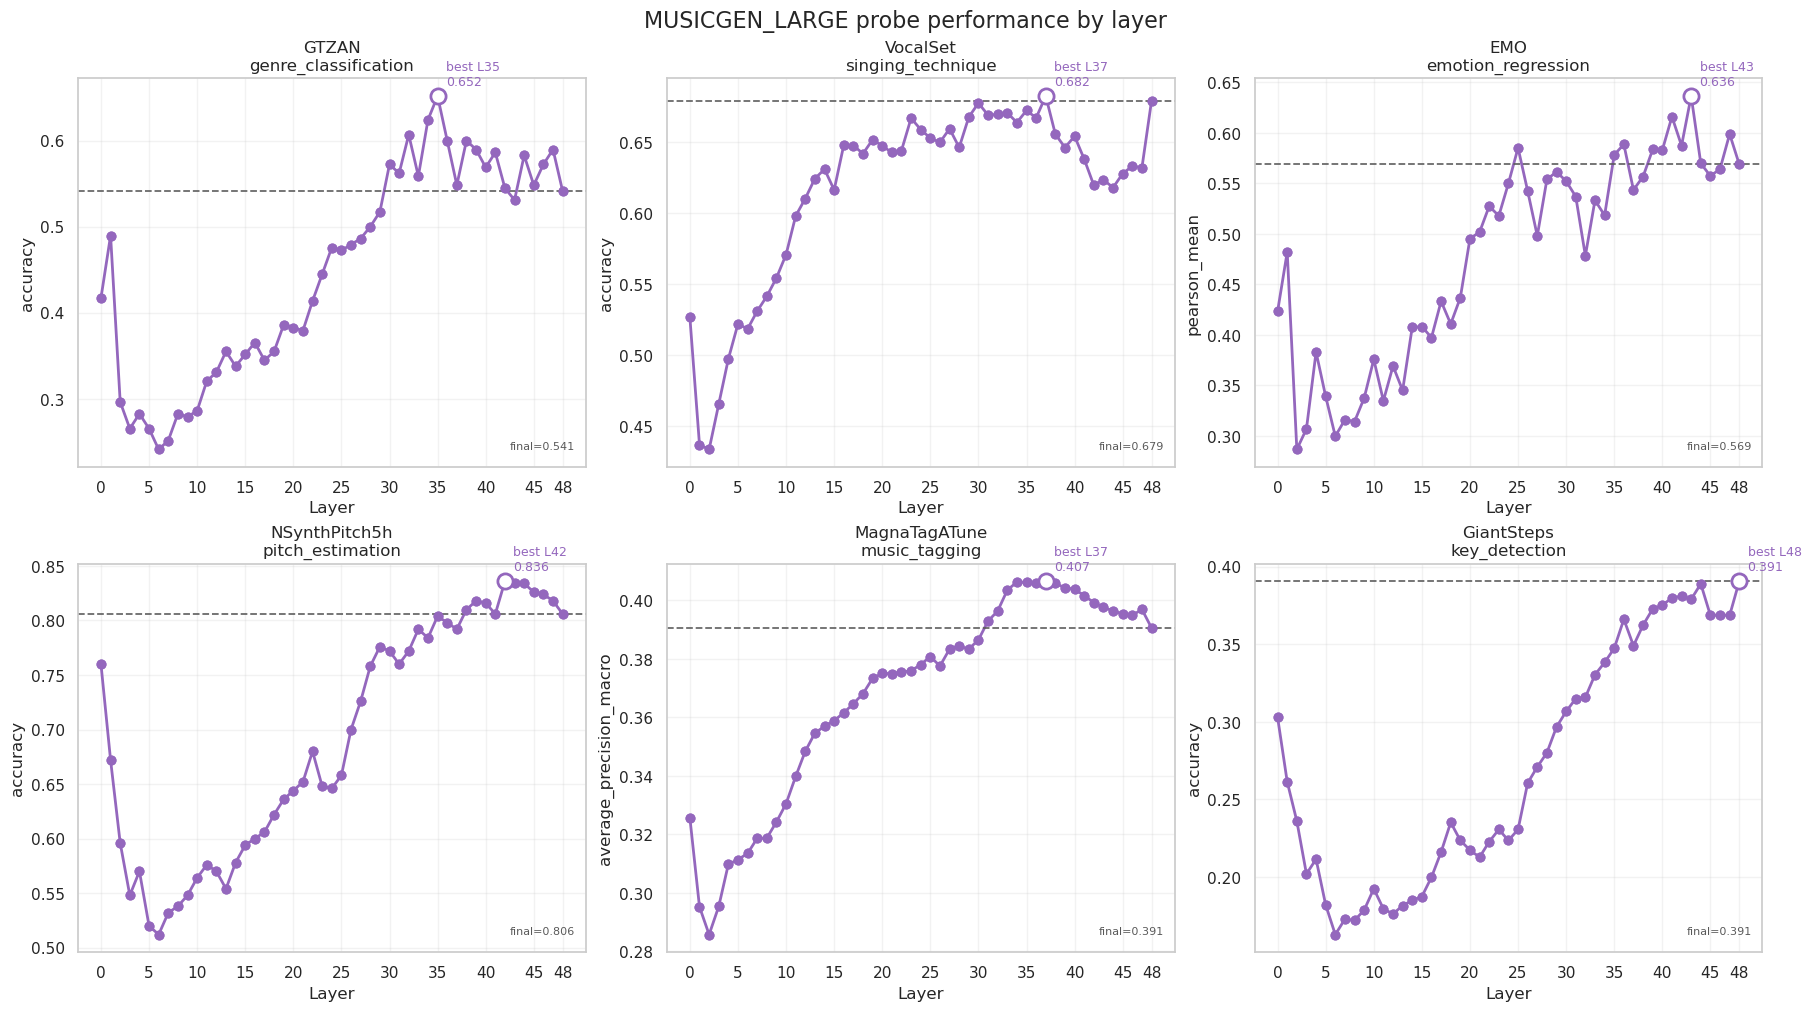

### MUSICGEN_MELODY_LARGE layer-wise probe performance

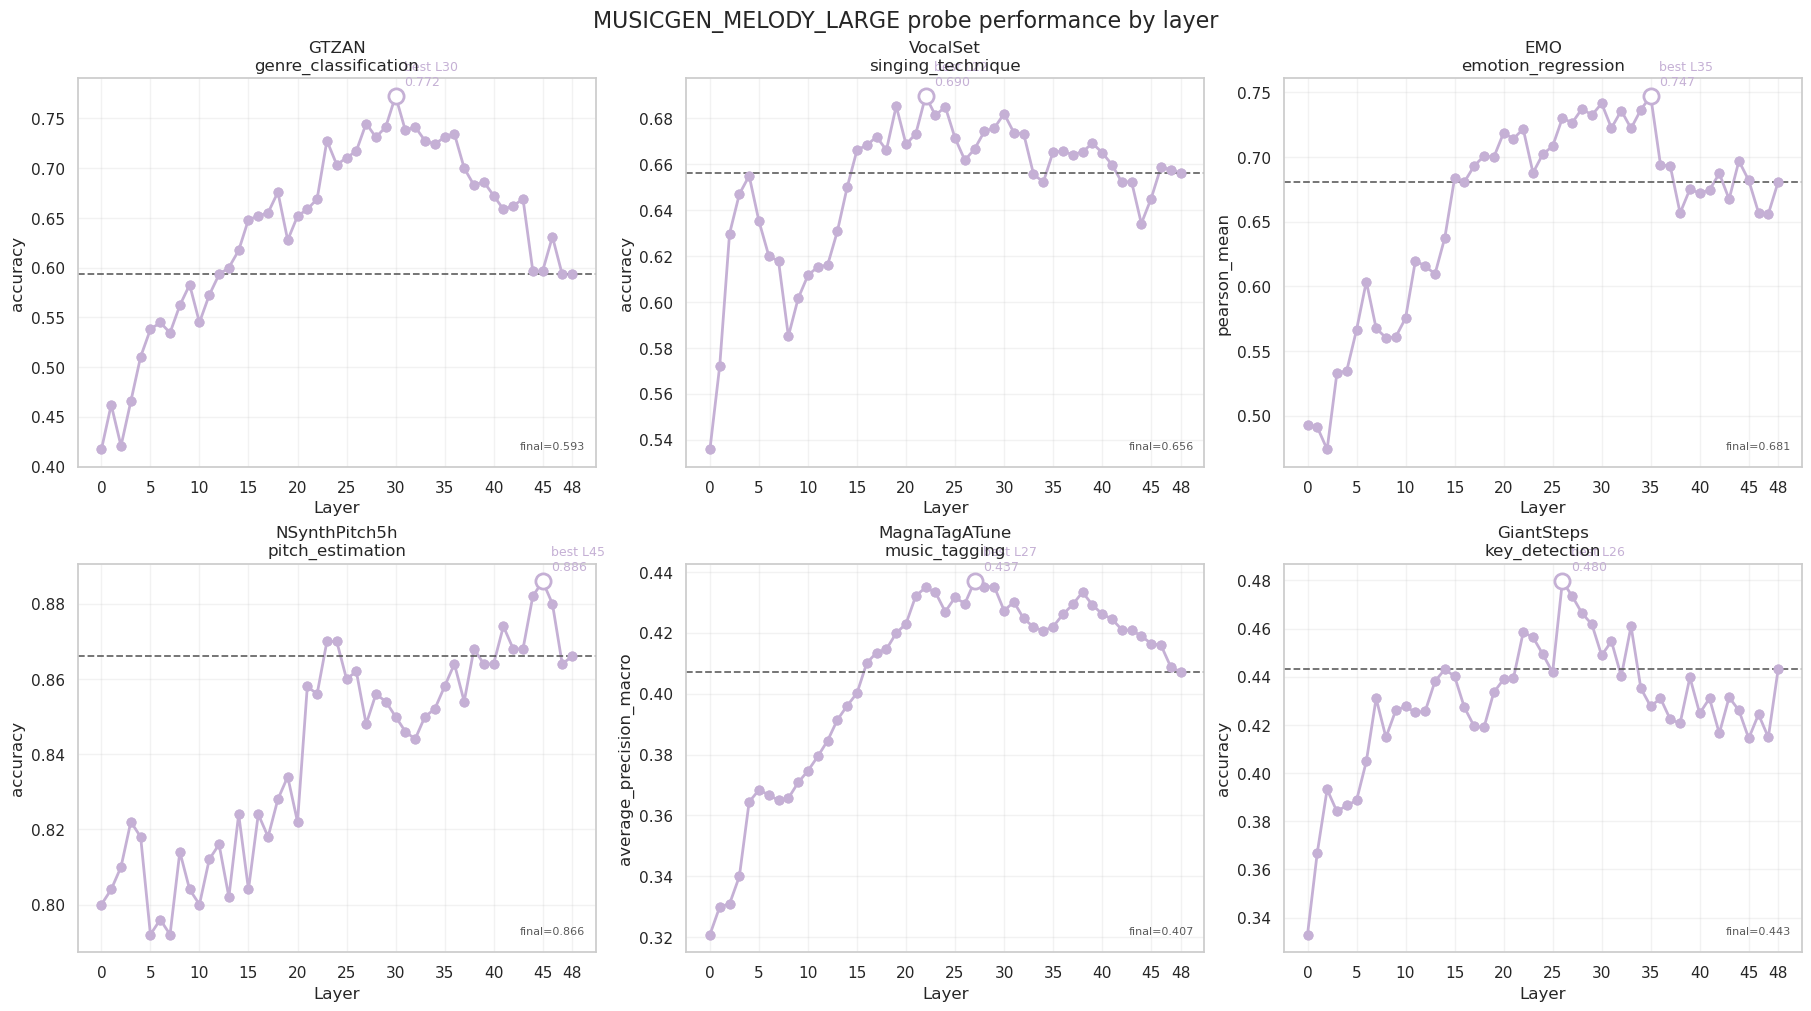

### WAV2VEC2 layer-wise probe performance

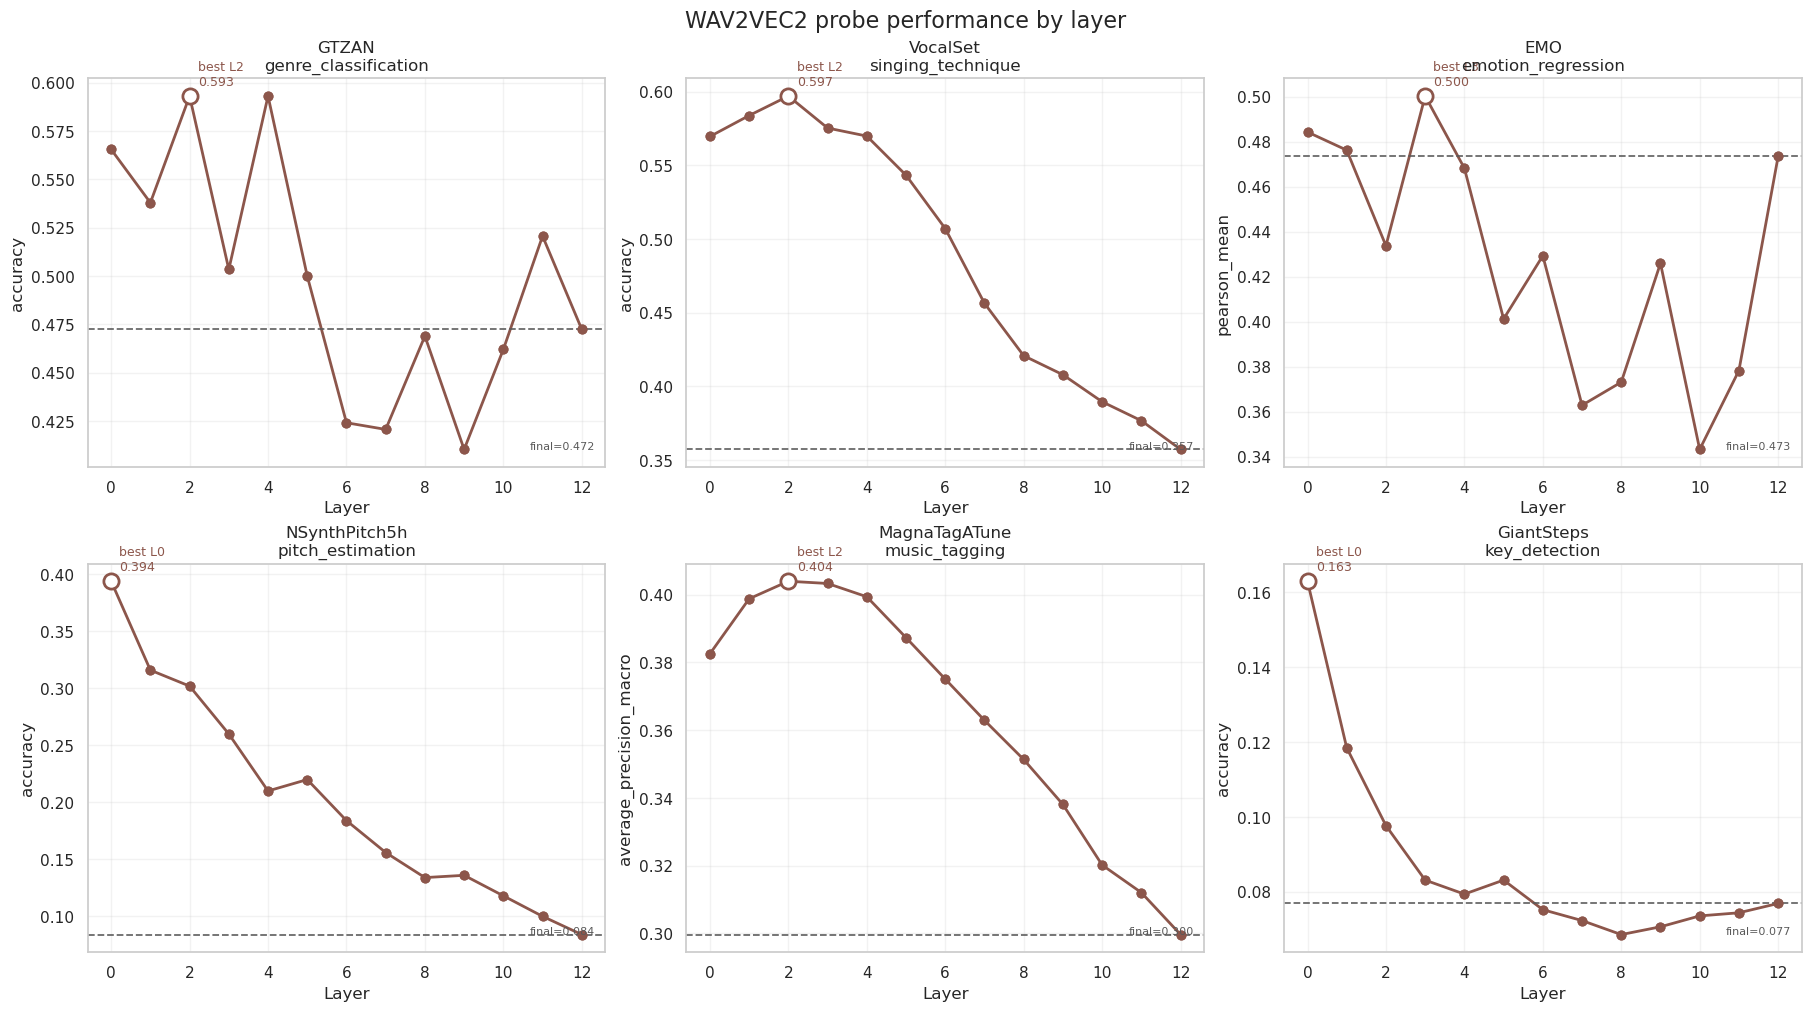

In [7]:
layer_only = summary[summary['layer_index'].notna()].copy()
final_only = summary[summary['is_final']].copy()

verified_layers = (
    layer_only.groupby(['dataset_task', 'model_name'], observed=True)
    .agg(
        n_layers=('layer_index', 'nunique'),
        first_layer=('layer_index', 'min'),
        last_layer=('layer_index', 'max'),
        metric=('primary_metric_name', 'first'),
    )
    .reset_index()
)
verified_layers[['n_layers', 'first_layer', 'last_layer']] = verified_layers[['n_layers', 'first_layer', 'last_layer']].astype(int)
display(Markdown('### Verified Numeric Layer Coverage'))
display(verified_layers)

last_layer_vs_final = (
    layer_only.sort_values('layer_index')
    .groupby(['dataset_task', 'model_name'], observed=True)
    .tail(1)[['dataset_task', 'model_name', 'representation_name', 'layer_index', 'primary_metric_value']]
    .rename(columns={
        'representation_name': 'last_layer_representation',
        'layer_index': 'last_layer_index',
        'primary_metric_value': 'last_layer_score',
    })
    .merge(
        final_only[['dataset_task', 'model_name', 'representation_name', 'primary_metric_value']].rename(columns={
            'representation_name': 'final_representation',
            'primary_metric_value': 'final_score',
        }),
        on=['dataset_task', 'model_name'],
        how='left',
    )
)
last_layer_vs_final['last_layer_index'] = last_layer_vs_final['last_layer_index'].astype(int)
last_layer_vs_final['delta_final_minus_last'] = last_layer_vs_final['final_score'] - last_layer_vs_final['last_layer_score']
display(Markdown('### Last Numeric Layer vs. Final Representation'))
display(last_layer_vs_final)

def render_layerwise_probe_grid(model_name: str) -> None:
    model_df = layer_only[layer_only['model_name'] == model_name].copy().sort_values(['dataset_task', 'layer_index'])
    final_df = final_only[final_only['model_name'] == model_name].copy()
    display(Markdown(f'### {model_name.upper()} layer-wise probe performance'))

    fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
    axes = axes.ravel()
    for ax, dataset_task in zip(axes, task_order):
        title_dataset, title_task = str(dataset_task).split(' / ', 1)
        subset = model_df[model_df['dataset_task'] == dataset_task].copy()
        final_subset = final_df[final_df['dataset_task'] == dataset_task].copy()

        if len(subset) == 0:
            ax.set_title(f'{title_dataset}\n{title_task}')
            ax.set_xlabel('Layer')
            ax.set_ylabel('Probe performance')
            continue

        x = subset['layer_index'].astype(int).to_numpy()
        y = subset['primary_metric_value'].to_numpy()
        metric_name = subset['primary_metric_name'].iloc[0]

        ax.plot(x, y, color=palette[model_name], linewidth=2.0, marker='o', markersize=6)
        ax.scatter(x, y, color=palette[model_name], s=40, zorder=3)

        best_row = subset.loc[subset['primary_metric_value'].idxmax()]
        best_layer = int(best_row['layer_index'])
        best_score = float(best_row['primary_metric_value'])
        ax.scatter([best_layer], [best_score], color='white', edgecolor=palette[model_name], linewidth=2, s=120, zorder=4)
        ax.annotate(
            f'best L{best_layer}\n{best_score:.3f}',
            xy=(best_layer, best_score),
            xytext=(6, 8),
            textcoords='offset points',
            fontsize=9,
            color=palette[model_name],
        )

        if len(final_subset):
            final_repr_name = str(final_subset['representation_name'].iloc[0])
            final_score = float(final_subset['primary_metric_value'].iloc[0])
            ax.axhline(final_score, color='0.35', linestyle='--', linewidth=1.3, alpha=0.9)
            ax.text(
                0.98,
                0.04,
                f'{final_repr_name}={final_score:.3f}',
                transform=ax.transAxes,
                ha='right',
                va='bottom',
                fontsize=8,
                color='0.35',
            )

        tick_step = max(1, int(np.ceil(len(x) / 10)))
        xticks = x[::tick_step]
        if xticks[-1] != x[-1]:
            xticks = np.append(xticks, x[-1])

        ax.set_title(f'{title_dataset}\n{title_task}')
        ax.set_xlabel('Layer')
        ax.set_ylabel(metric_name)
        ax.set_xticks(xticks)
        ax.grid(alpha=0.25)

    fig.suptitle(f'{model_name.upper()} probe performance by layer', fontsize=16)
    plt.show()

display(Markdown('## Layer-wise Probe Performance Overview'))
for model_name in model_order:
    render_layerwise_probe_grid(model_name)


In [8]:
def render_model_view(model_name: str) -> None:
    model_df = plot_layerwise[plot_layerwise['model_name'] == model_name].copy()
    display(Markdown(f'## {model_name.upper()}'))

    corr_rows = []
    if len(model_df) >= 3:
        pearson_all = pearsonr(model_df['alignment_score'], model_df['primary_metric_value'])
        spearman_all = spearmanr(model_df['alignment_score'], model_df['primary_metric_value'])
        corr_rows.append({
            'dataset_task': 'ALL_TASKS',
            'n_points': int(len(model_df)),
            'pearson_r': float(pearson_all.statistic),
            'pearson_p': float(pearson_all.pvalue),
            'spearman_rho': float(spearman_all.statistic),
            'spearman_p': float(spearman_all.pvalue),
        })
    for dataset_task in task_order:
        subset = model_df[model_df['dataset_task'] == dataset_task]
        if len(subset) < 3:
            continue
        pearson_task = pearsonr(subset['alignment_score'], subset['primary_metric_value'])
        spearman_task = spearmanr(subset['alignment_score'], subset['primary_metric_value'])
        corr_rows.append({
            'dataset_task': dataset_task,
            'n_points': int(len(subset)),
            'pearson_r': float(pearson_task.statistic),
            'pearson_p': float(pearson_task.pvalue),
            'spearman_rho': float(spearman_task.statistic),
            'spearman_p': float(spearman_task.pvalue),
        })
    display(pd.DataFrame(corr_rows))

    fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
    axes = axes.ravel()
    for ax, dataset_task in zip(axes, task_order):
        subset = model_df[model_df['dataset_task'] == dataset_task].copy().sort_values(['layer_order'])
        if len(subset) == 0:
            ax.set_title(dataset_task)
            ax.set_xlabel(score_label)
            ax.set_ylabel('Primary probe metric')
            continue

        ax.plot(
            subset['alignment_score'],
            subset['primary_metric_value'],
            color=palette[model_name],
            linewidth=1.6,
            alpha=0.35,
        )
        ax.scatter(
            subset['alignment_score'],
            subset['primary_metric_value'],
            color=palette[model_name],
            s=np.where(subset['is_final'], 110, 32),
            alpha=np.where(subset['is_final'], 0.9, 0.45),
        )
        final_points = subset[subset['is_final']]
        for _, row in final_points.iterrows():
            ax.text(row['alignment_score'], row['primary_metric_value'], model_name.upper(), fontsize=9, ha='left', va='bottom')

        if len(subset) >= 3:
            x = subset['alignment_score'].to_numpy()
            y = subset['primary_metric_value'].to_numpy()
            slope, intercept = np.polyfit(x, y, deg=1)
            x_line = np.linspace(float(np.min(x)), float(np.max(x)), 100)
            y_line = slope * x_line + intercept
            pearson_task = pearsonr(x, y)
            ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.0, alpha=0.9)
            ax.text(
                0.03,
                0.97,
                f"r={pearson_task.statistic:.3f}\np={pearson_task.pvalue:.3g}",
                transform=ax.transAxes,
                ha='left',
                va='top',
                fontsize=9,
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.8', alpha=0.9),
            )

        ax.set_title(dataset_task)
        ax.set_xlabel(score_label)
        ax.set_ylabel('Primary probe metric')

    fig.suptitle(f'{model_name.upper()} layer-wise alignment vs. performance ({ALIGNMENT_KIND})', fontsize=16)
    plt.show()

## CLAP

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,36,0.457531,0.005022,0.344455,0.039665
1,GTZAN / genre_classification,6,0.965441,0.001771,0.257143,0.622787
2,VocalSet / singing_technique,6,0.911508,0.011400,0.314286,0.544093
3,EMO / emotion_regression,6,0.666096,0.148624,0.714286,0.110787
4,NSynthPitch5h / pitch_estimation,6,0.664158,0.150245,0.885714,0.018845
5,MagnaTagATune / music_tagging,6,0.887956,0.018127,0.085714,0.871743
6,GiantSteps / key_detection,6,0.132659,0.802178,0.485714,0.328723


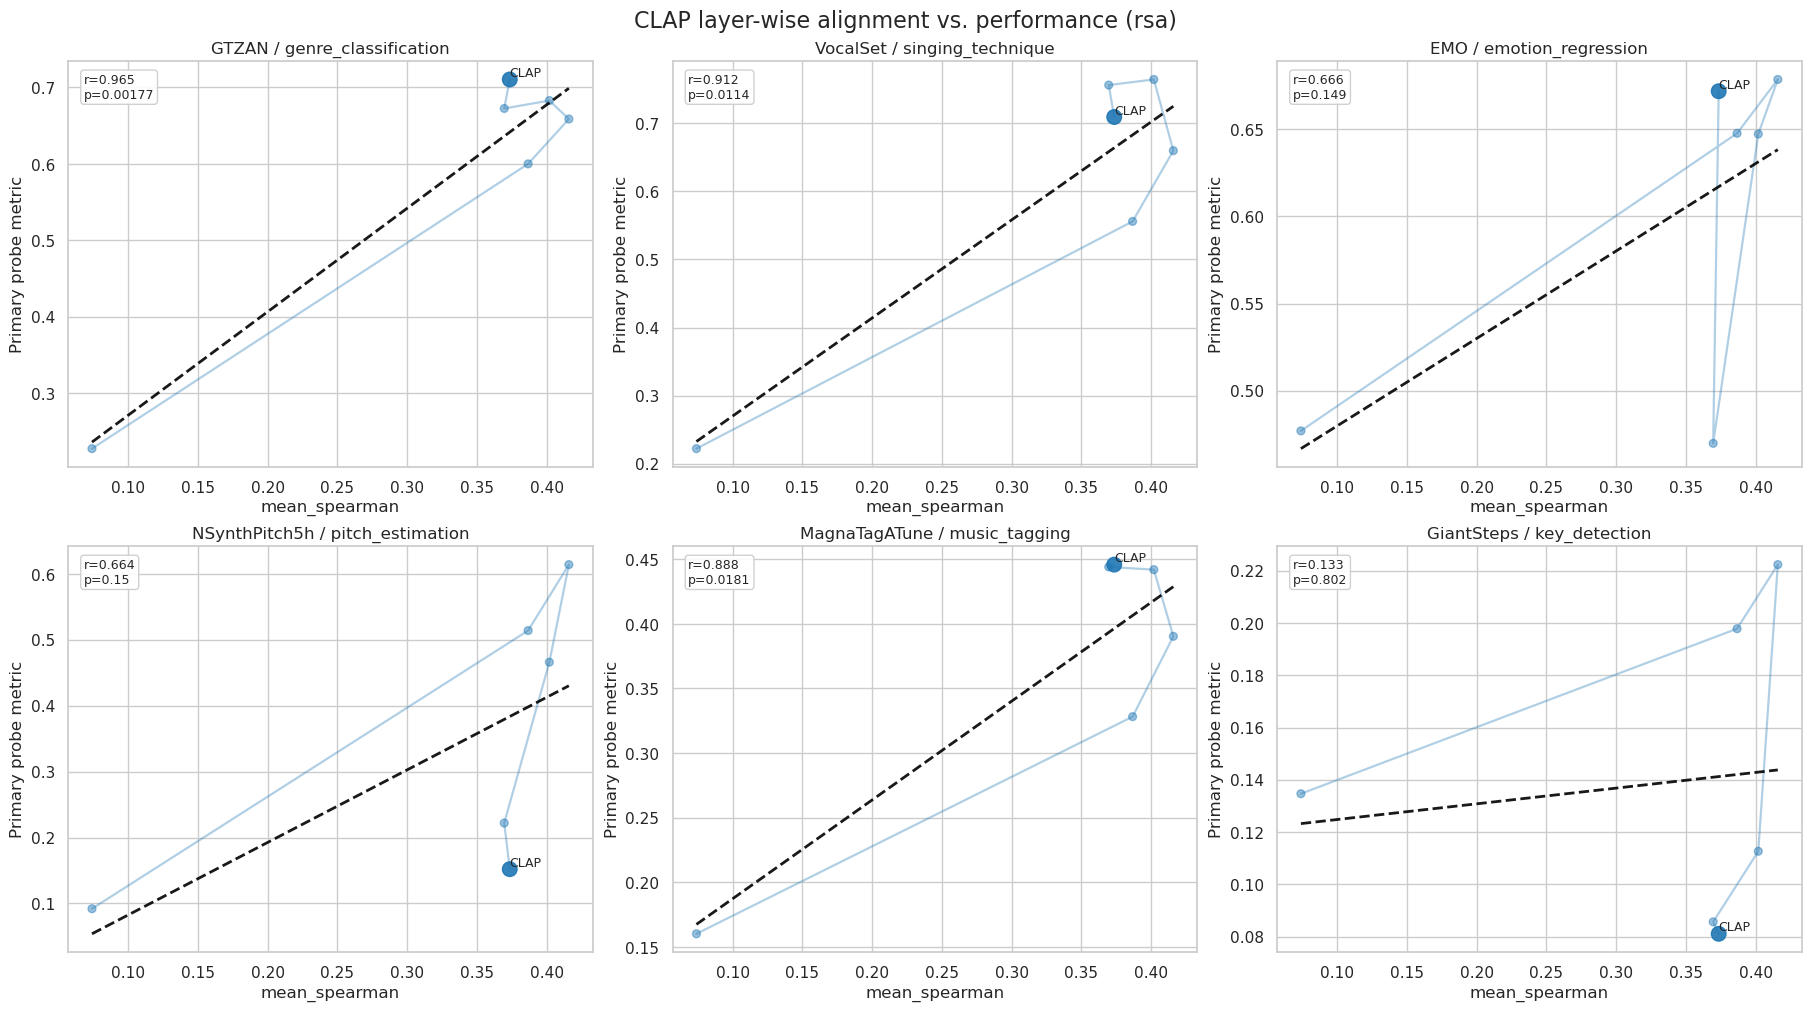

## CLAP_MUSIC

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,36,-0.398945,0.015943,-0.346871,0.038208
1,GTZAN / genre_classification,6,-0.189698,0.718867,-0.231908,0.658374
2,VocalSet / singing_technique,6,-0.708918,0.114762,-0.371429,0.468478
3,EMO / emotion_regression,6,-0.084462,0.873608,-0.085714,0.871743
4,NSynthPitch5h / pitch_estimation,6,-0.897914,0.015100,-0.637748,0.173071
5,MagnaTagATune / music_tagging,6,-0.922465,0.008785,-0.428571,0.396501
6,GiantSteps / key_detection,6,-0.953263,0.003225,-0.985611,0.000309


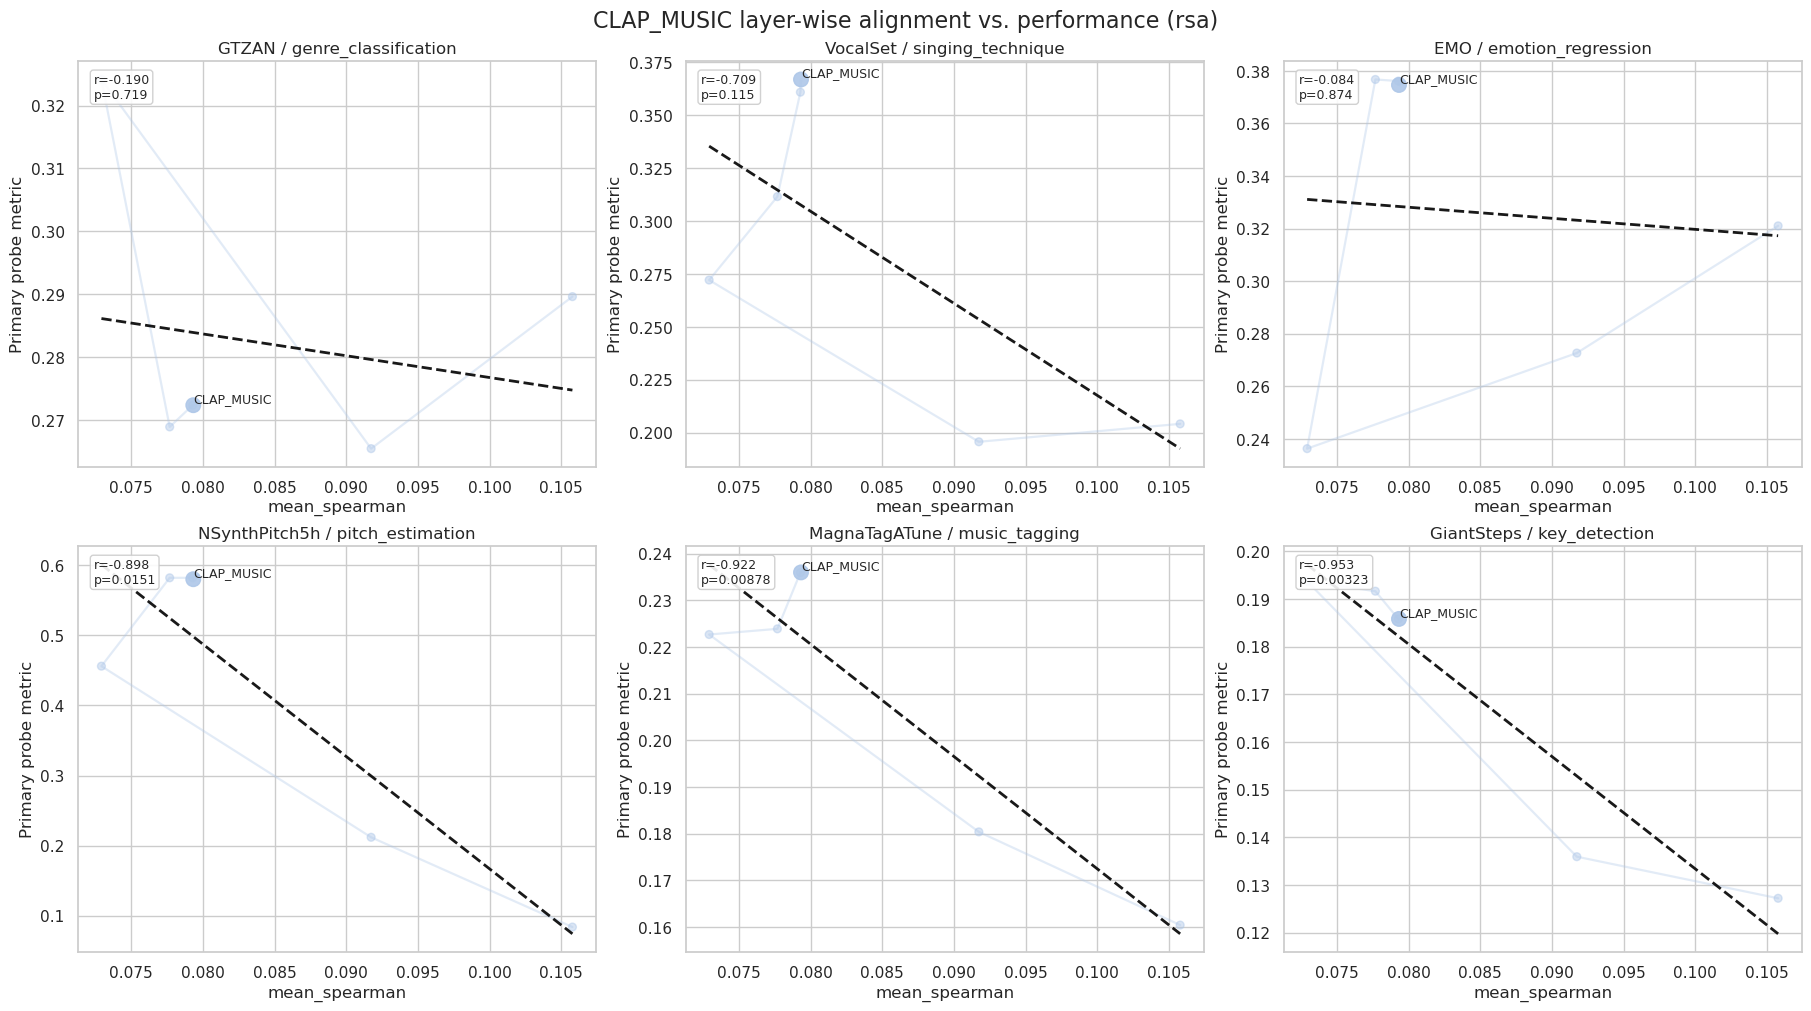

## CLAP_MUSIC_SPEECH

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,36,0.453378,0.005487,0.328036,0.050798
1,GTZAN / genre_classification,6,0.947930,0.003996,0.521794,0.288343
2,VocalSet / singing_technique,6,0.952184,0.003375,0.828571,0.041563
3,EMO / emotion_regression,6,0.899168,0.014738,0.314286,0.544093
4,NSynthPitch5h / pitch_estimation,6,0.669273,0.145983,0.542857,0.265703
5,MagnaTagATune / music_tagging,6,0.929612,0.007257,0.542857,0.265703
6,GiantSteps / key_detection,6,0.069535,0.895866,-0.085714,0.871743


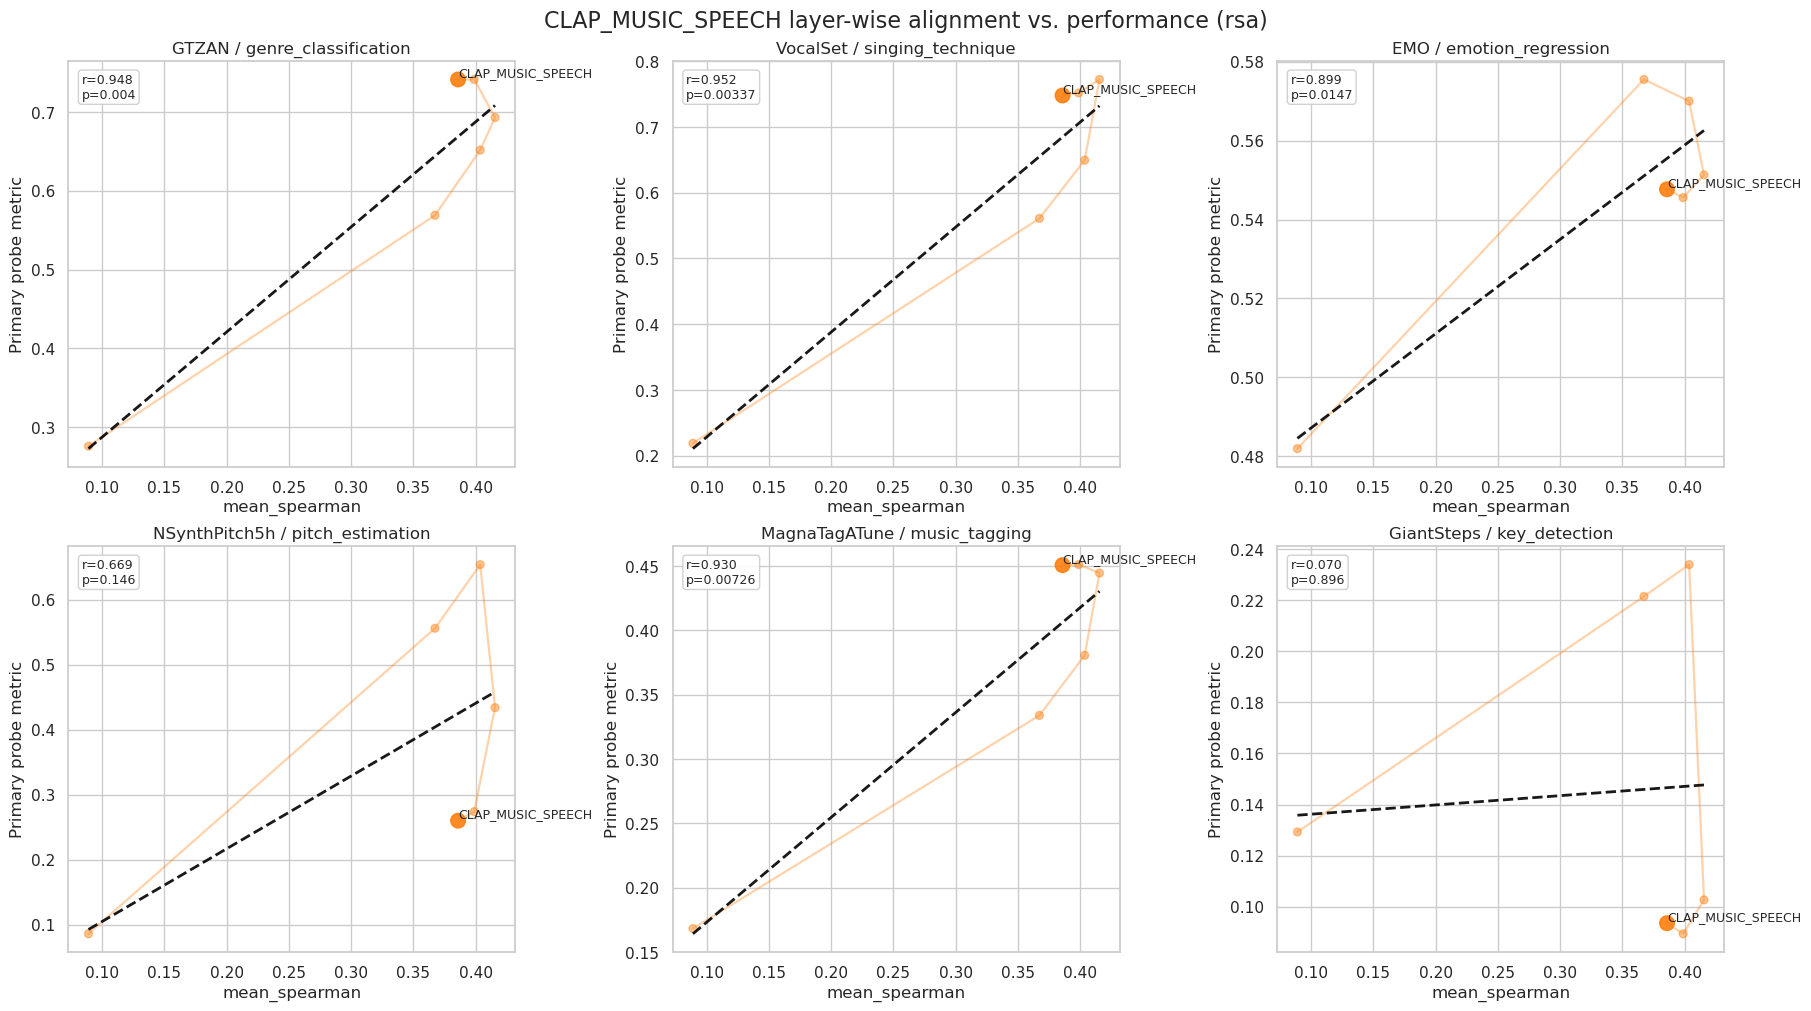

## MULAN

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,84,0.099303,0.368804,0.087572,0.428296
1,GTZAN / genre_classification,14,-0.109880,0.708452,-0.103410,0.724991
2,VocalSet / singing_technique,14,0.710605,0.004393,0.661538,0.009975
3,EMO / emotion_regression,14,-0.248794,0.391049,0.134066,0.647720
4,NSynthPitch5h / pitch_estimation,14,0.518374,0.057560,0.243956,0.400625
5,MagnaTagATune / music_tagging,14,0.337218,0.238377,0.028571,0.922761
6,GiantSteps / key_detection,14,0.761767,0.001545,0.569231,0.033619


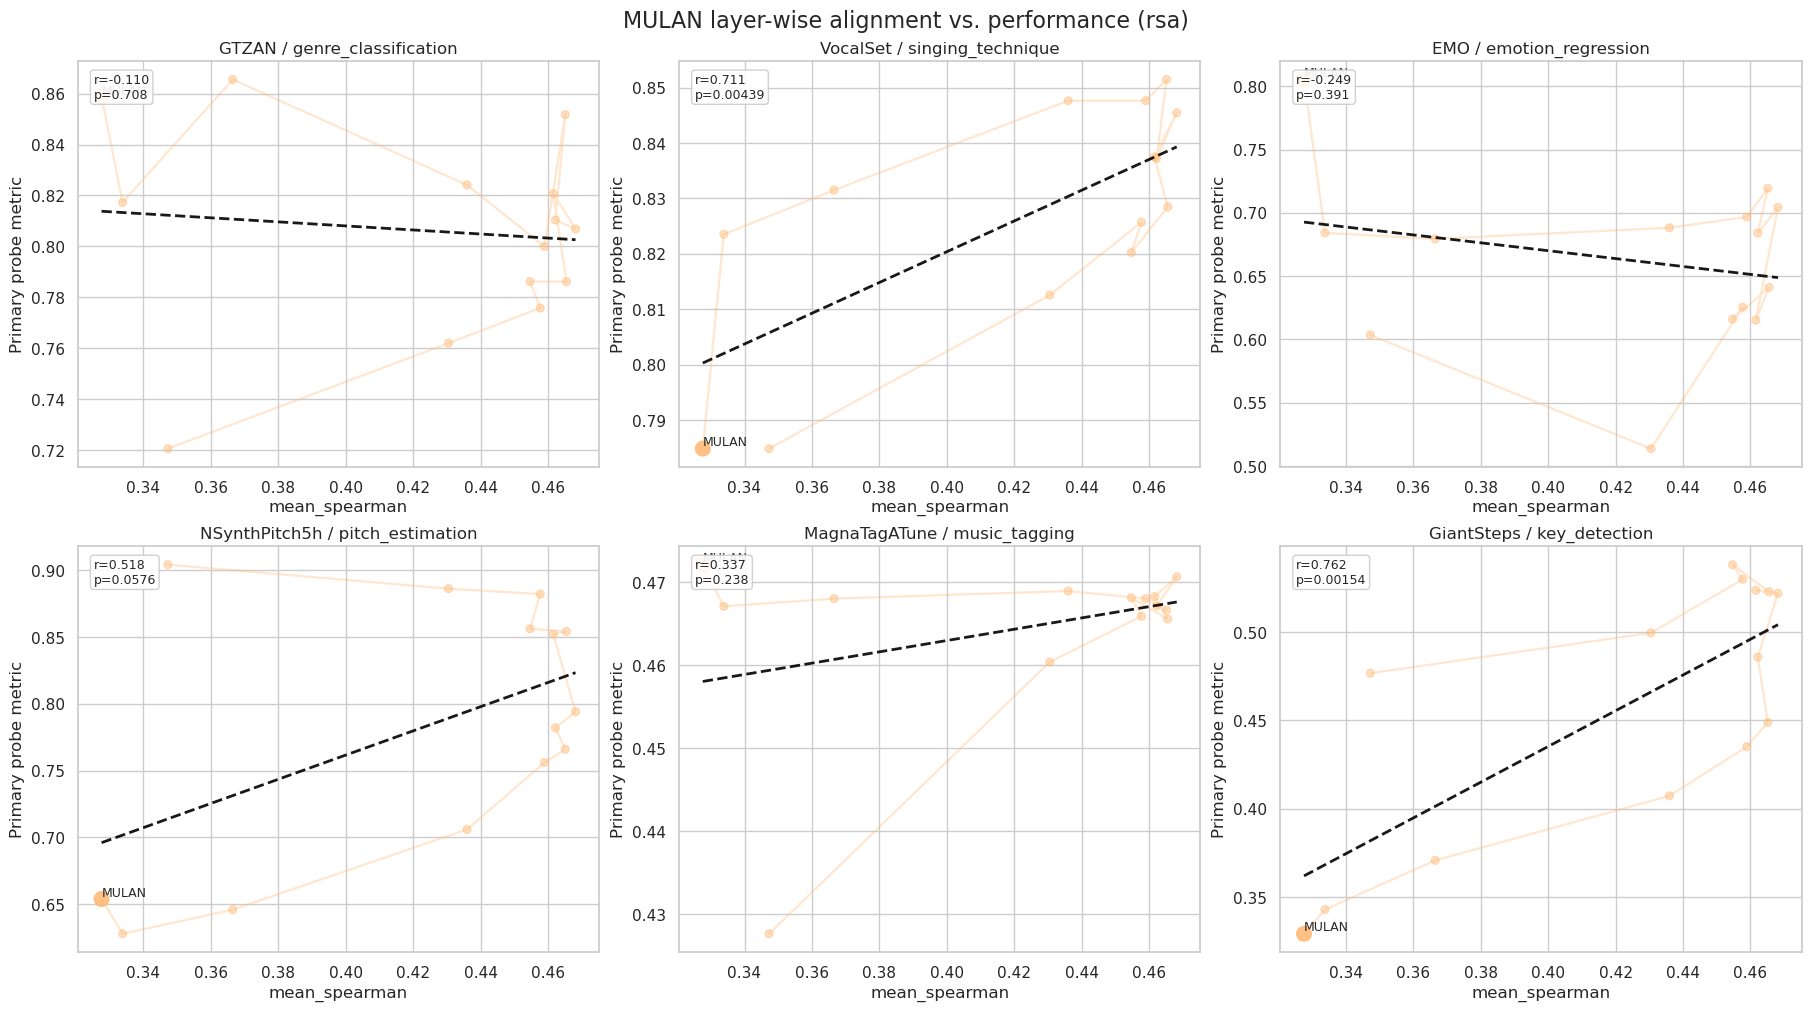

## MERT

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,156,0.079704,3.226301e-01,0.088908,0.269714
1,GTZAN / genre_classification,26,0.222658,2.742634e-01,0.230098,0.258128
2,VocalSet / singing_technique,26,0.823476,2.379541e-07,0.727086,0.000026
3,EMO / emotion_regression,26,0.223064,2.733673e-01,0.150479,0.463100
4,NSynthPitch5h / pitch_estimation,26,0.670858,1.761938e-04,0.510537,0.007700
5,MagnaTagATune / music_tagging,26,0.474982,1.420494e-02,0.517784,0.006742
6,GiantSteps / key_detection,26,0.719175,3.475889e-05,0.671455,0.000173


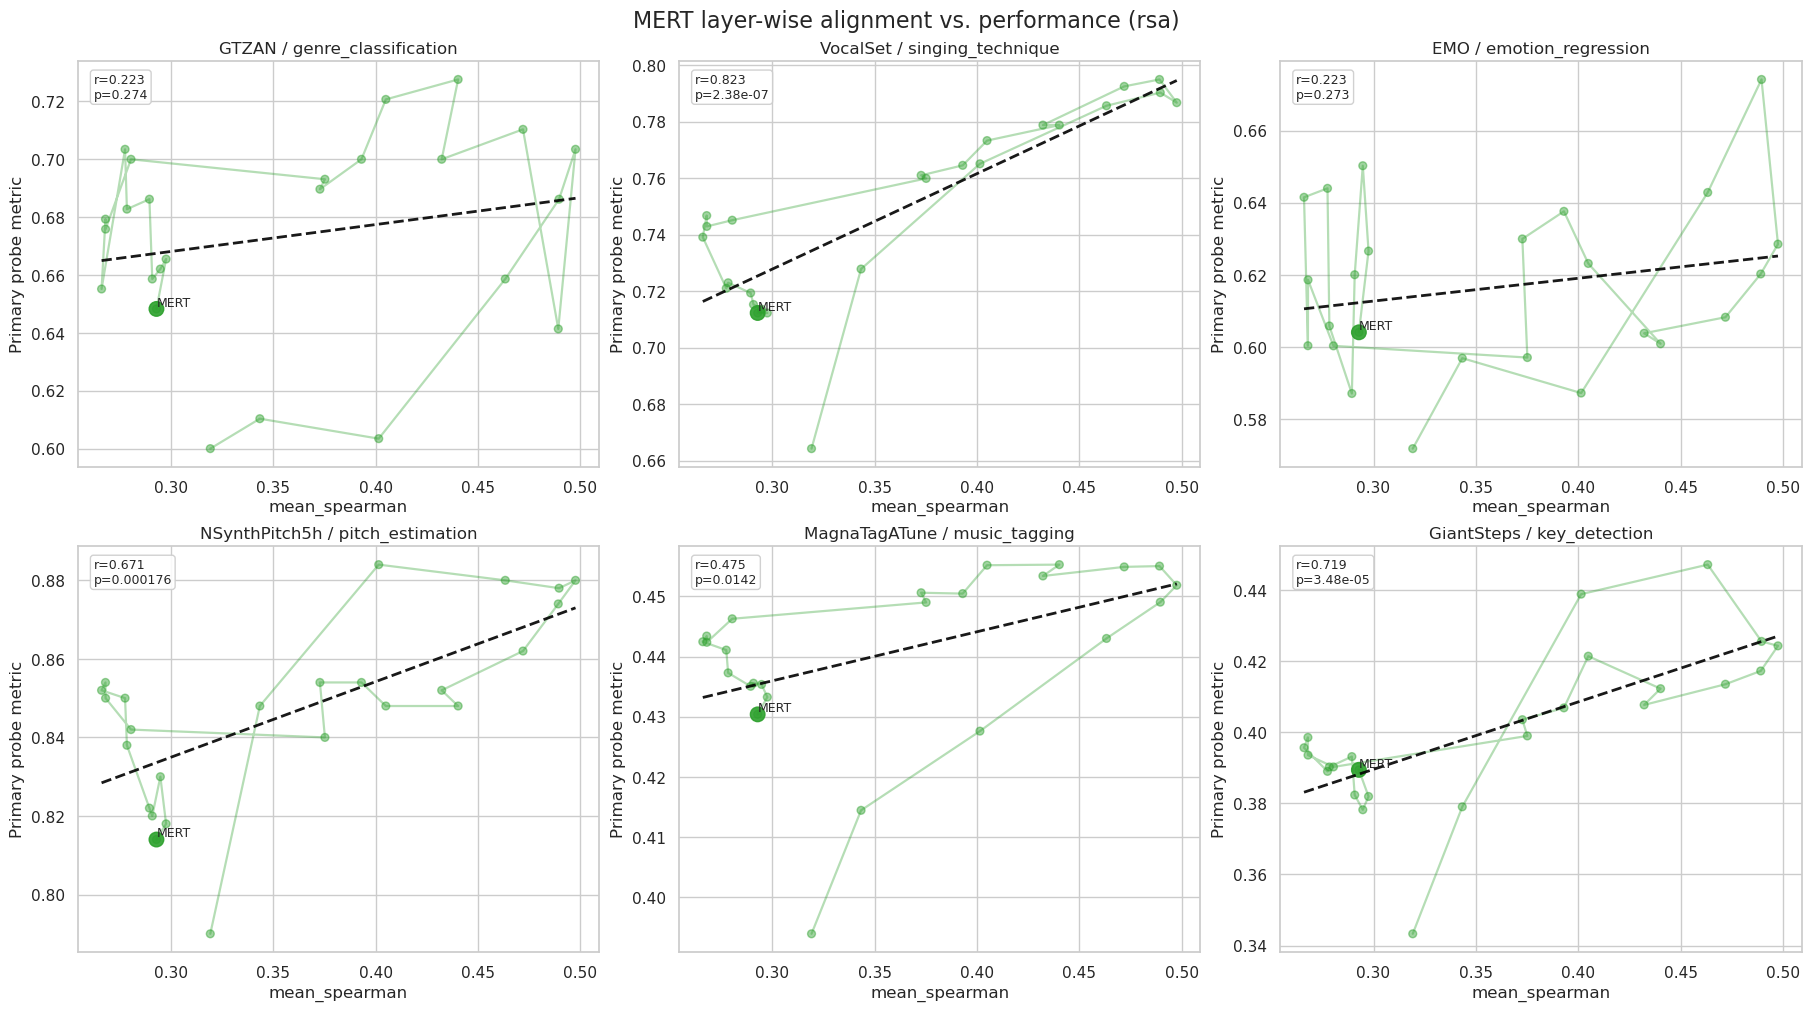

## MERT95

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,84,0.060034,0.587496,0.070236,0.525515
1,GTZAN / genre_classification,14,0.519095,0.057152,0.423842,0.130973
2,VocalSet / singing_technique,14,0.809540,0.000451,0.779736,0.001007
3,EMO / emotion_regression,14,0.435265,0.119821,0.440529,0.114905
4,NSynthPitch5h / pitch_estimation,14,-0.444303,0.111468,-0.411508,0.143776
5,MagnaTagATune / music_tagging,14,0.758100,0.001678,0.669604,0.008804
6,GiantSteps / key_detection,14,0.030211,0.918341,-0.149780,0.609300


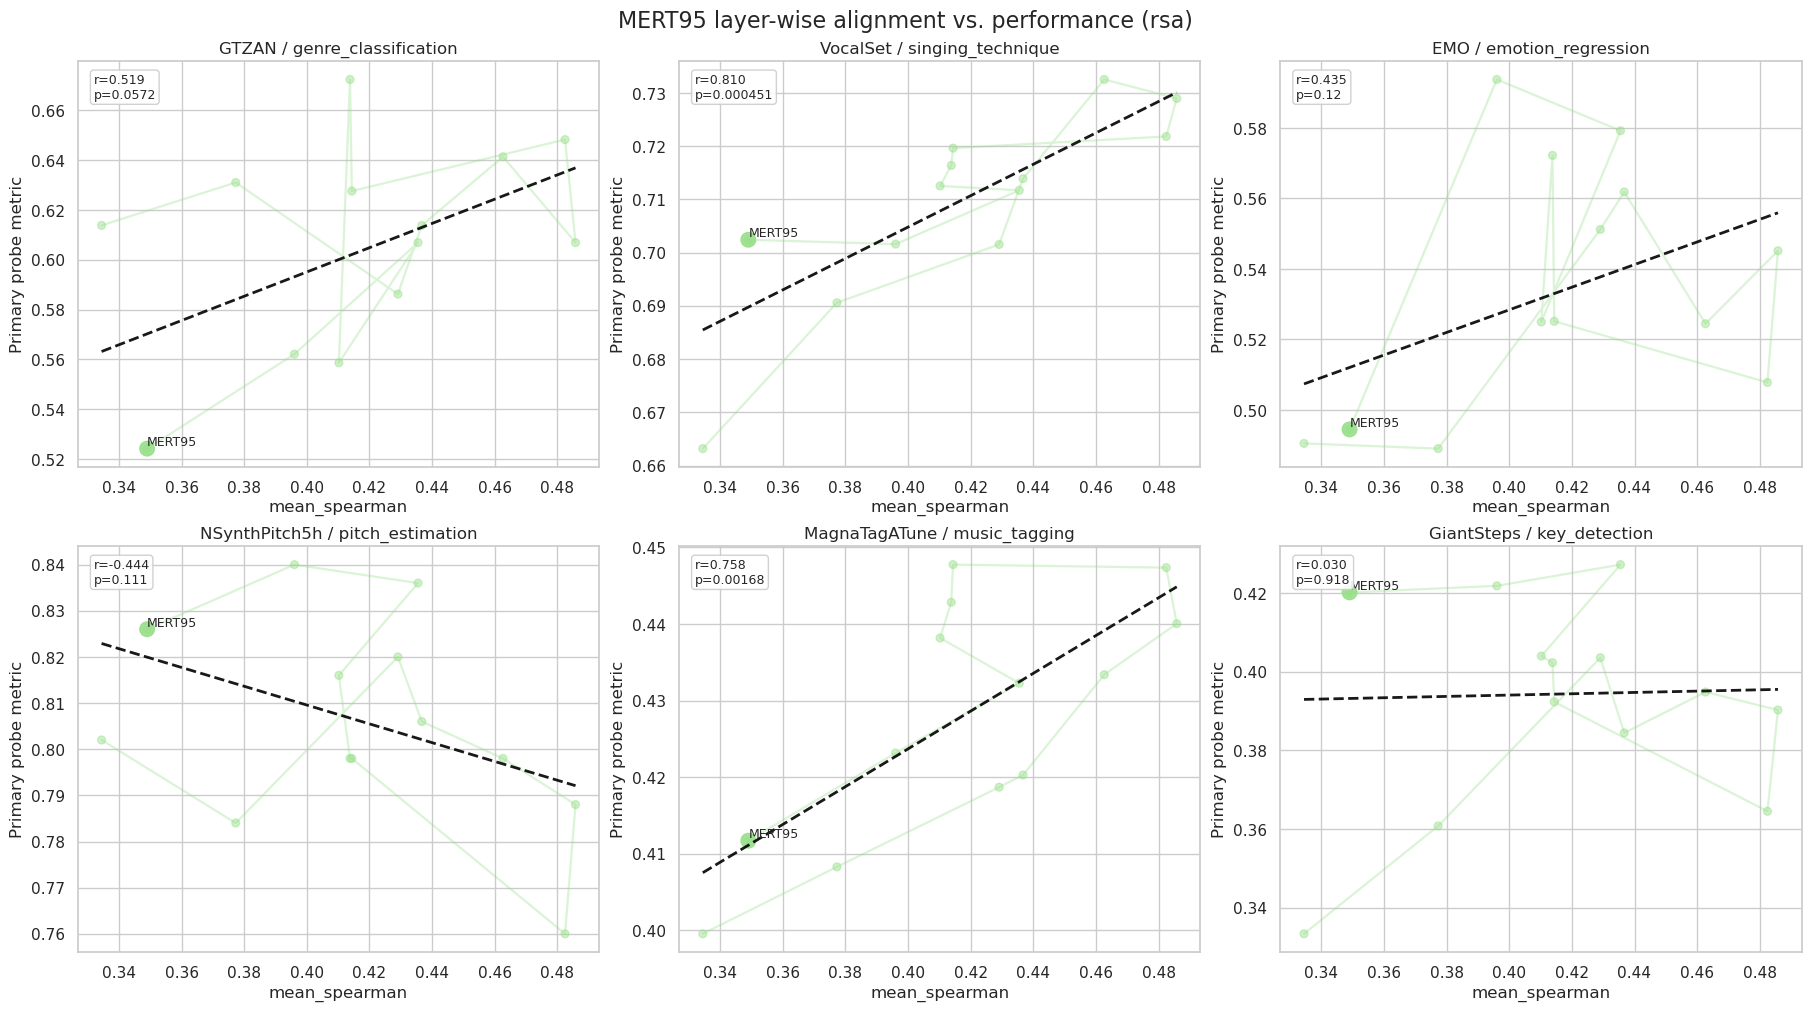

## MUSICGEN_SMALL

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,156,0.129475,0.107196,0.122509,1.276136e-01
1,GTZAN / genre_classification,26,0.549240,0.003660,0.674093,1.595146e-04
2,VocalSet / singing_technique,26,0.616307,0.000801,0.510260,7.738760e-03
3,EMO / emotion_regression,26,0.338975,0.090264,0.214090,2.936260e-01
4,NSynthPitch5h / pitch_estimation,26,0.533758,0.004980,0.176743,3.877411e-01
5,MagnaTagATune / music_tagging,26,0.726735,0.000026,0.883721,2.201100e-09
6,GiantSteps / key_detection,26,0.599465,0.001210,0.288159,1.534206e-01


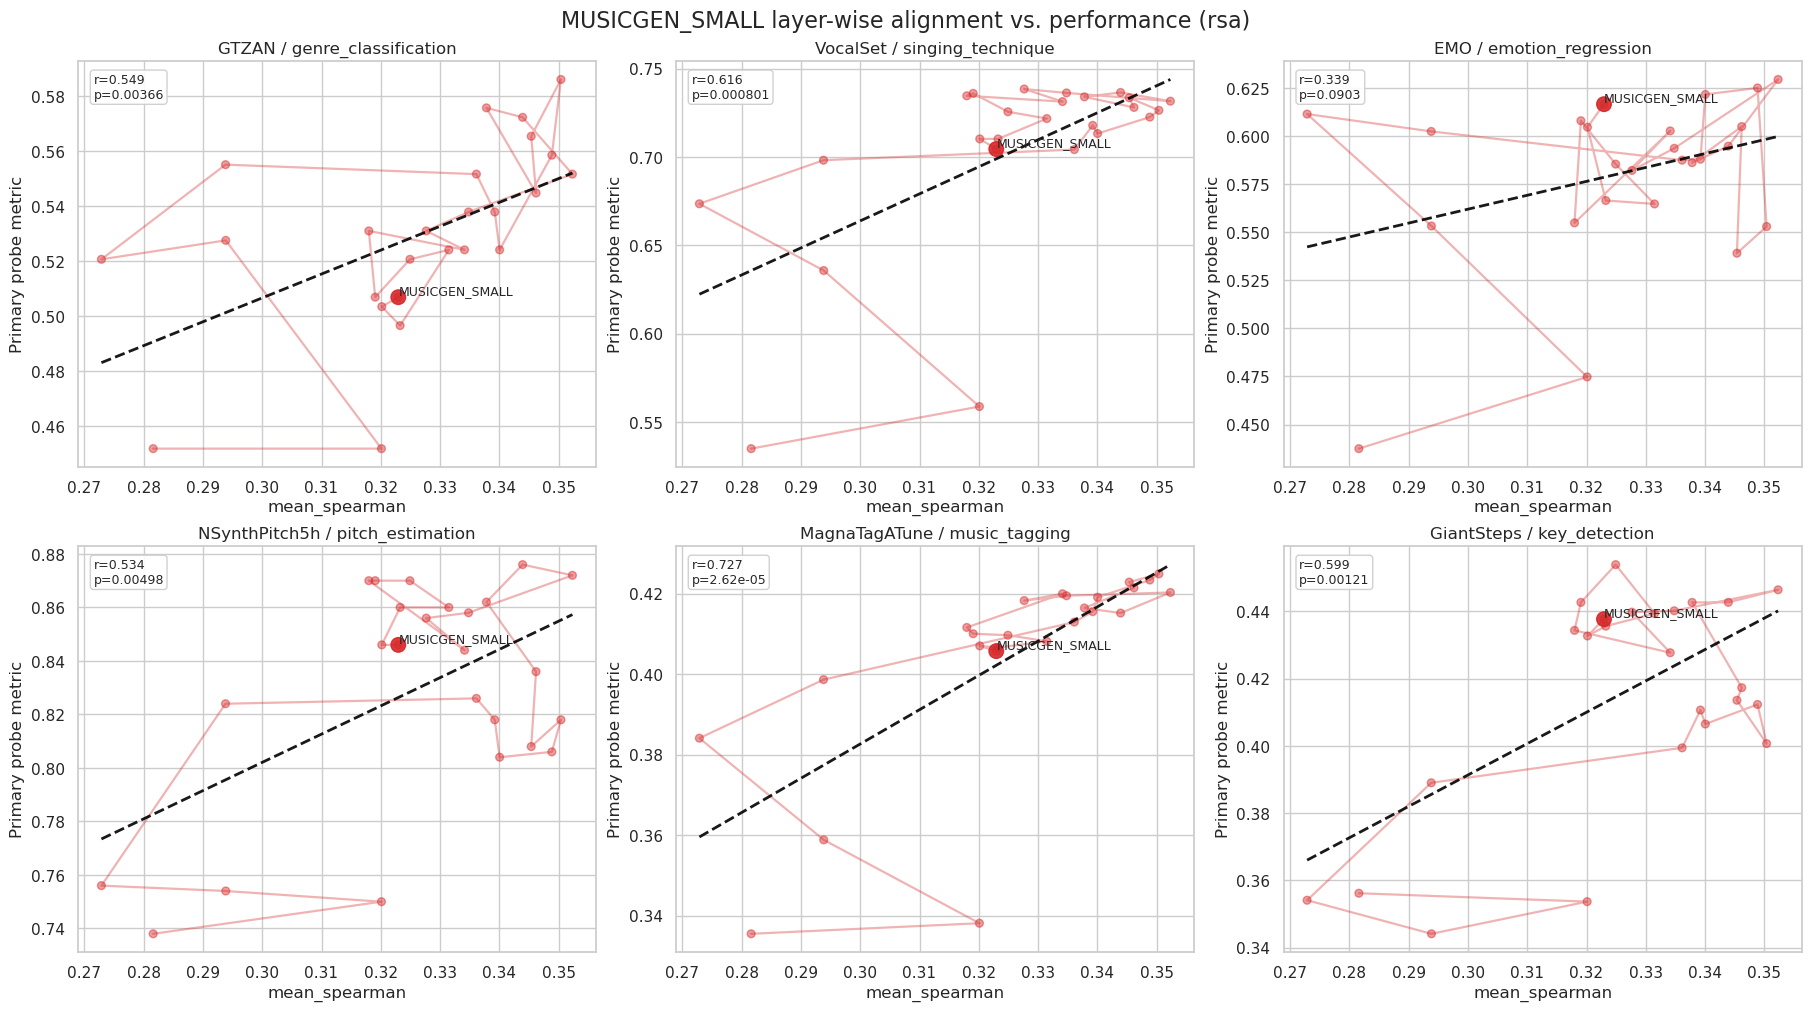

## MUSICGEN_MEDIUM

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,300,0.341061,1.315245e-09,0.341064,1.314909e-09
1,GTZAN / genre_classification,50,0.881715,2.824029e-17,0.755200,2.344123e-10
2,VocalSet / singing_technique,50,0.438372,1.451544e-03,0.573761,1.325254e-05
3,EMO / emotion_regression,50,0.802453,2.436634e-12,0.663561,1.504573e-07
4,NSynthPitch5h / pitch_estimation,50,0.903709,2.615498e-19,0.834026,5.455786e-14
5,MagnaTagATune / music_tagging,50,0.686106,3.814251e-08,0.657799,2.097679e-07
6,GiantSteps / key_detection,50,0.855837,2.404196e-15,0.778917,2.723729e-11


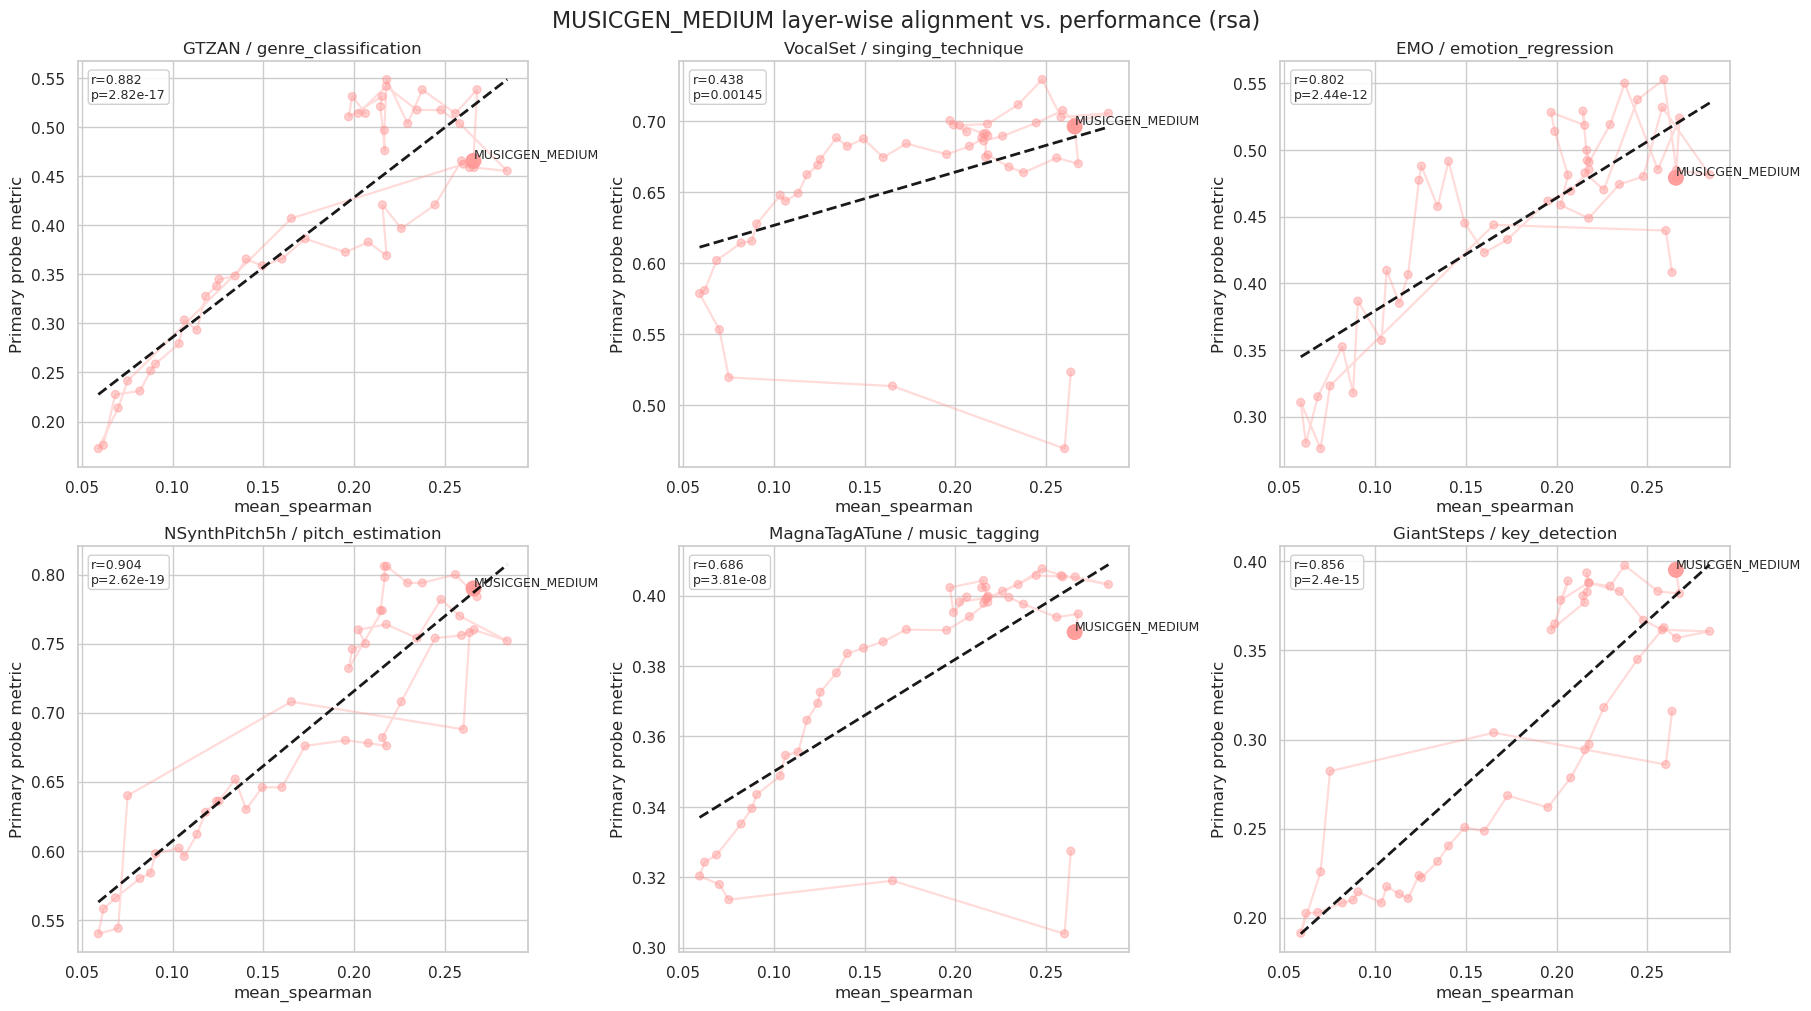

## MUSICGEN_LARGE

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,300,0.419826,3.076853e-14,0.429079,7.227221e-15
1,GTZAN / genre_classification,50,0.938456,8.412757e-24,0.938210,9.230986e-24
2,VocalSet / singing_technique,50,0.407716,3.293378e-03,0.549750,3.546900e-05
3,EMO / emotion_regression,50,0.802246,2.492288e-12,0.805801,1.683679e-12
4,NSynthPitch5h / pitch_estimation,50,0.950903,4.275663e-26,0.903165,2.975217e-19
5,MagnaTagATune / music_tagging,50,0.704433,1.138795e-08,0.870246,2.275890e-16
6,GiantSteps / key_detection,50,0.955570,4.100601e-27,0.907816,9.634438e-20


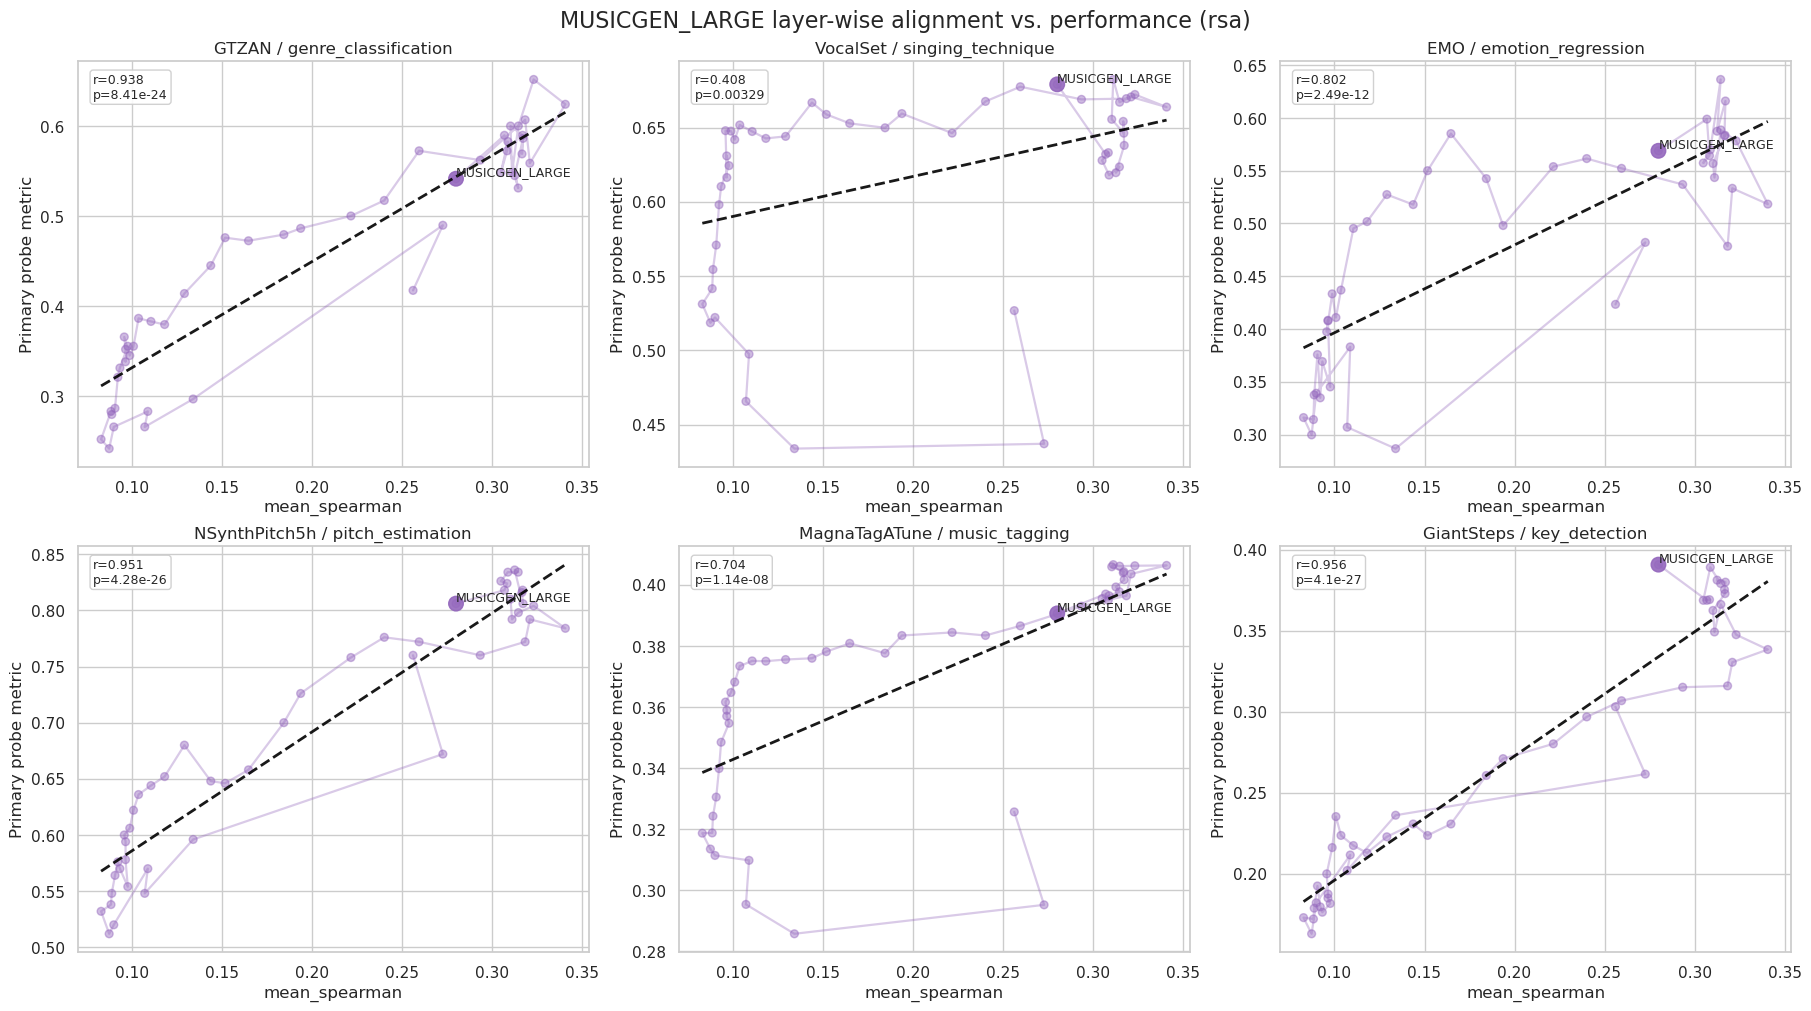

## MUSICGEN_MELODY_LARGE

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,300,0.137998,1.677188e-02,0.198314,5.504381e-04
1,GTZAN / genre_classification,50,0.410775,3.044999e-03,0.543105,4.596920e-05
2,VocalSet / singing_technique,50,0.338729,1.611926e-02,0.319919,2.352253e-02
3,EMO / emotion_regression,50,0.514403,1.326269e-04,0.489723,3.067182e-04
4,NSynthPitch5h / pitch_estimation,50,0.776086,3.569868e-11,0.873474,1.291127e-16
5,MagnaTagATune / music_tagging,50,0.581114,9.650457e-06,0.566366,1.809441e-05
6,GiantSteps / key_detection,50,0.306422,3.044234e-02,0.311742,2.753595e-02


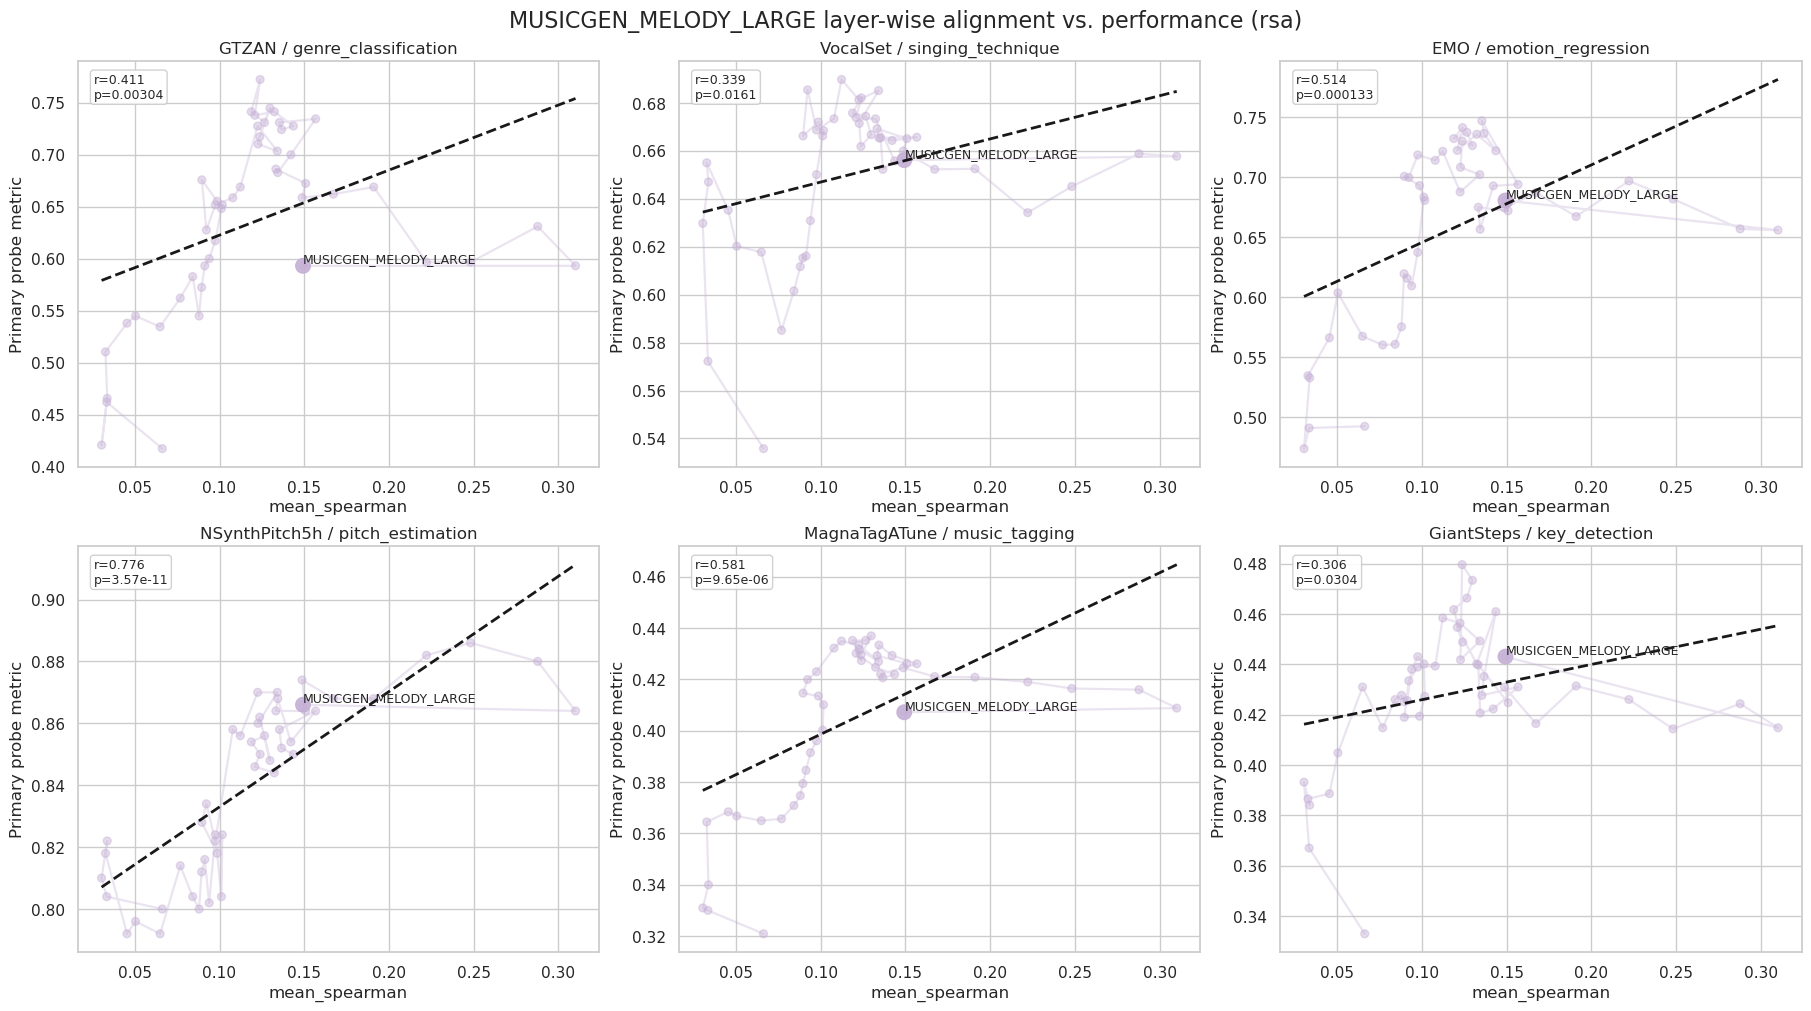

## WAV2VEC2

,dataset_task,n_points,pearson_r,pearson_p,spearman_rho,spearman_p
0,ALL_TASKS,84,0.222709,0.041728,0.267101,0.014044
1,GTZAN / genre_classification,14,0.465025,0.093841,0.471886,0.088460
2,VocalSet / singing_technique,14,0.822654,0.000303,0.863436,0.000069
3,EMO / emotion_regression,14,0.447216,0.108862,0.370044,0.192810
4,NSynthPitch5h / pitch_estimation,14,0.649768,0.011895,0.757709,0.001693
5,MagnaTagATune / music_tagging,14,0.816227,0.000370,0.889868,0.000020
6,GiantSteps / key_detection,14,0.252663,0.383479,0.637266,0.014233


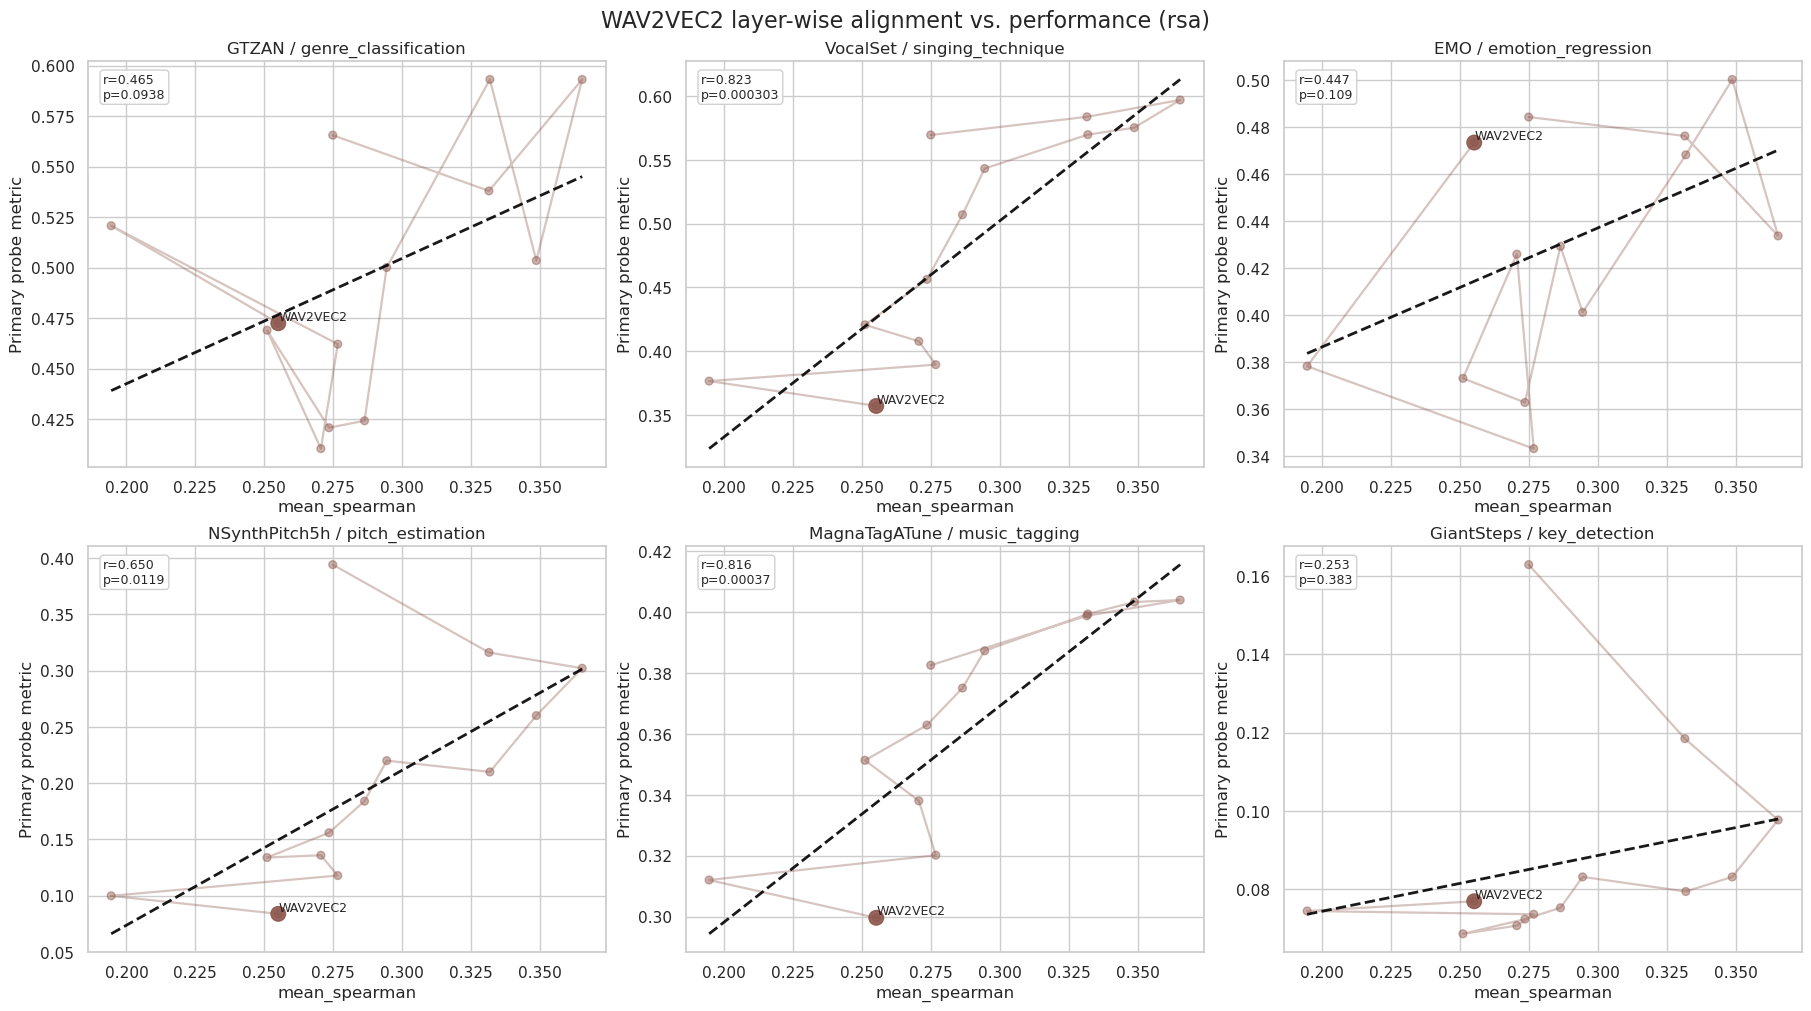

In [9]:
for model_name in model_order:
    render_model_view(model_name)